# Машинное обучение, <a href="https://thetahat.ru/courses/ds-group">DS-поток</a>
## Задание ML.1

**Правила:**

* Дедлайны см. студенческом кабинете. После дедлайна работы не принимаются кроме случаев наличия уважительной причины.
* Прислать нужно **ноутбук в формате `ipynb`**.
* Следите за размером файлов. **Сайт не может принимать файлы весом более 50 Мб.** Если файл получается больше, заранее разделите его на несколько.
* Выполнять задание необходимо полностью самостоятельно. **При обнаружении списывания все участники списывания будут сдавать устный зачет.**
* Решения, размещенные на каких-либо интернет-ресурсах, не принимаются. Кроме того, публикация решения в открытом доступе может быть приравнена к предоставлении возможности списать.
* Для выполнения задания используйте этот ноутбук в качестве основы, **не исправляйте и не удаляйте условия!** Можно добавлять необходимое количество ячеек.
* Комментарии к решению пишите в markdown-ячейках.
* Выполнение задания (ход решения, выводы и пр.) должно быть осуществлено на русском языке.
* Решение проверяется системой ИИ-проверки <a href="https://thetahat.ru/"><img src="https://miptstats.github.io/theta_grader_small.png" style="display: inline; vertical-align: middle;"></a> **ThetaGrader**. Результат проверки валидируется и исправляется человеком, после чего комментарии отправляются студентам.
* Если код будет не понятен проверяющему, оценка может быть снижена.
* Никакой код из данного задания при проверке запускаться не будет. *Если код студента не выполнен, недописан и т.д., то он не оценивается.*
* В каждой задаче не забывайте делать **пояснения и выводы**.


**Правила оформления теоретических задач:**

* Решения необходимо прислать в виде $\LaTeX$ в markdown-ячейках.
* В решениях поясняйте, чем вы пользуетесь, хотя бы кратко. Например, если пользуетесь независимостью, то достаточно подписи вида "*X и Y незав.*"
* Решение, в котором есть только ответ, и отсутствуют вычисления, оценивается в 0 баллов.

**Баллы за задание:**

* Задача 1 &mdash; 15 баллов;
* Задача 2 &mdash; 35 баллов;
* Задача 3 &mdash; 30 баллов;
* Задача 4 &mdash; 100 баллов;

----

### Ссылки на использование ИИ

Если при решении задач использовался ИИ, укажи здесь публичные ссылки на все чаты с ИИ и поясни, для каких целей он применялся. Обрати внимание на <a href="https://thetahat.ru/courses/ai-rules" target="_top">правила</a>.

**Задача 1**
1. https://share.google/aimode/bRVyYHFYPppWug8r8
    - вопрос по теху

**Задача 2**
1. https://chat.deepseek.com/share/f4lab8s5a3zpdeiynh
    - исправление теха


**Задача 4**
1. https://share.google/aimode/mMzMmrR5hsSrwW03c
    - как использовать l1_ratio = 0.5 - пополам на пополам регуляризации и L1, и L2 в ElasticNet
2. https://share.google/aimode/gnTbqRjRGjhm8aRoB
- Как собственные значения посчитать np.linalg?
- Как SVD разложение сделать np.linalg?
- Пусть есть ось X, у нее log scale, на ней стоит отметка x = 10^33, что это значит какое значение x в обычной шкале? 10^33 или 33?
- Как сделать подписи на матрице корреляций (значение корреляции?)?
- пусть X - data_frame в pandas, X - матрица n * d, n - объектов, d - признаков, как взять jый признак легко?
- как понять j-ый признак это вещественная фича или категориальная?
- Правда ли, что если собственное значение матрицы A = lambda_0, то собственное значение матрицы A + \lambda * I, где I - Identity Matrix, это будет lambda_0 + lambda, если да, то докажи

3. https://chat.deepseek.com/a/chat/s/1ac1515e-b856-4a0b-9d61-d5520a6b5775
- Каждую модель надо обучить 500 раз при различных разбиениях на обучающую и тестовую выборки. -- то есть это в каждой из итераций надо делать train_test_split()? А Random seed при этом одинаковым должен быть или нет?
- Детали работы ShuffleSplit
- Обсуждение KFold

In [1]:
# Bot check

# HW_ID: ds_ml1
# Бот проверит этот ID и предупредит, если случайно сдать что-то не то.

# Status: not final
# Перед отправкой в финальном решении удали "not" в строчке выше.
# Так бот проверит, что ты отправляешь финальную версию, а не промежуточную.
# Никакие значения в этой ячейке не влияют на факт сдачи работы.

In [2]:
import numpy as np
import pandas as pd
import scipy.stats as sps
import scipy
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import accuracy_score, root_mean_squared_error
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from time import time
from tqdm.notebook import tqdm
from typing import Tuple, List, Dict, Any, Optional

sns.set_theme(palette='Set2', font_scale=1.2)

RANDOM_SEED = 42 # фиксируем зерно случайности для 4ой задачи

---
### Задача 1.

Выведите итерационную формулу пересчета коэффициентов модели с помощью формулы решения через проксимальный оператор для Ridge-регрессии. Что можно сказать о влиянии параметра регуляризации?

Рассмотрим основную задачу $\min\limits_{\theta} \Phi(\theta) = F(\theta) + \lambda R(\theta)$, где:

* $F(\theta) = \text{MSE} = ||y - X \theta||_2^2$ в качестве основного лосса взяли MSE
* $R(\theta) = \text{L2-норма весов} = ||\theta||_2^2$ в качестве регуляризации взяли Ridge (L2)

Хотя обе эти функции являются и выпуклыми, и гладкими, можно для такой задачи оптимизации применять обычный градиентный / стохастический градиентный спуск, но поработаем с проксимальным оператором и увидим какого эффекта можно добиться, если применить его к этой задаче минимизации:

**Вспомним определение:** для выпуклой функции $f$ определен проксимальный оператор

$\text{Pr}_f(p) = arg \min\limits_{x} (\frac{1}{2} \cdot ||x - p||_2^2 + f(x))$

**Условие оптимальности (того, что точка $x_0$ является минимумом):**

$x_0 = \text{Pr}_f(p) \Longleftrightarrow 0 \in x_0 - p + \partial f(x_0)$, просто взяли производную из определения выше

**Итерация проксимального градиента для основной задачи:**

1) Input: входные данные и инициализация параметров $\alpha, \lambda$
2) пересчет весов как через обычный GD: $\theta_t - \alpha \nabla F(\theta_t)$
3) Навешивание на это все проксимального оператора (для эффекта регуляризации)

Общая формула:
$\theta_{t + 1} = \text{Pr}_{\alpha \lambda R}(\theta_t - \alpha \nabla F(\theta_t))$

**Работаем с нашими функциями**

* $F(\theta) = \text{MSE} = ||y - X \theta||_2^2$
* $R(\theta) = \text{L2-норма весов} = ||\theta||_2^2$

1) градиент для $F = $ MSE известен с лекции, $\nabla_{\theta} F = 2 X^T (X\theta - y)$
2) можно делать шаг как в GD: $\theta_t - \alpha \nabla F(\theta_t) = \theta_t - \alpha 2 (y - X\theta_t)$
3) Разберемся с проксимальным оператором для функции $\alpha \lambda R(\theta) = \alpha \lambda ||\theta||_2^2$

$\text{Pr}_{\alpha \lambda ||\theta||_2^2}(p) = arg \min\limits_{x} (\frac{1}{2} \cdot ||x - p||_2^2 + \alpha \lambda ||x||_2^2)$

Надо минимум найти, поскольку под знаком arg min, обе функции гладкие и выпуклые, то можно как учит нас матанализ взять производные и приравнять к нулю в поисках $x^{*}$ = arg min.

Пусть $A = ||x - p||_2^2$, $B = ||x||_2^2$

$\nabla_{x} A = 2 (x - p), \nabla_{x} B = 2 x$

Тогда вся производная $x - p + 2 \alpha \lambda x = 0 \Longleftrightarrow x^{*} = \frac{p}{1 + 2 \alpha \lambda}$

Тогда $\text{Pr}_{\alpha \lambda ||\theta||_2^2}(p) = x^{*} = \frac{p}{1 + 2 \alpha \lambda}$, то есть проксимальный оператор для функции L2 нормы (регуляризации) - это есть просто гомотетия с коэффициентом $\frac{1}{1 + 2 \alpha \lambda}$

4) Итоговая итерационная формула пересчета коэффициентов модели с помощью проксимального оператора

$\theta_{t + 1} = \text{Pr}_{\alpha \lambda ||.||_2^2}(\theta_t - 2 \alpha X^T (X\theta - y)) \Longleftrightarrow \theta_{t + 1} = \frac{\theta_t - 2 \alpha X^T (X\theta_t - y)}{1 + 2 \alpha \lambda}$

5) Что можно сказать о влиянии параметра регуляризации:

$\lambda$ находится в знаментале, если оно большое, то веса будут на него нормироваться и не будут разрастаться, то есть он повышает устойчивость модели, хотя и не утягивает веса в чистый ноль, как это сделал проксимальный оператор для L1

Если $\lambda = 0$, то это обычный МНК (Метод Наименьших квадратов, минимизация MSE) без регуляризации

---
### Задача 2.

Исследуем Elastic-регрессию.

**1.** Визуализируйте множество, которое ограничивает коэффициенты в Elastic-регрессии.

На лекции мы видели такие множества для L1 и L2 реугуляризаций с помощью знания об ограниченной формы задачи и знания о том, что линии уровня квадрата ошибок выглядят как эллипсы с центром в точке $\hat{\theta}_{\text{МНК}}$

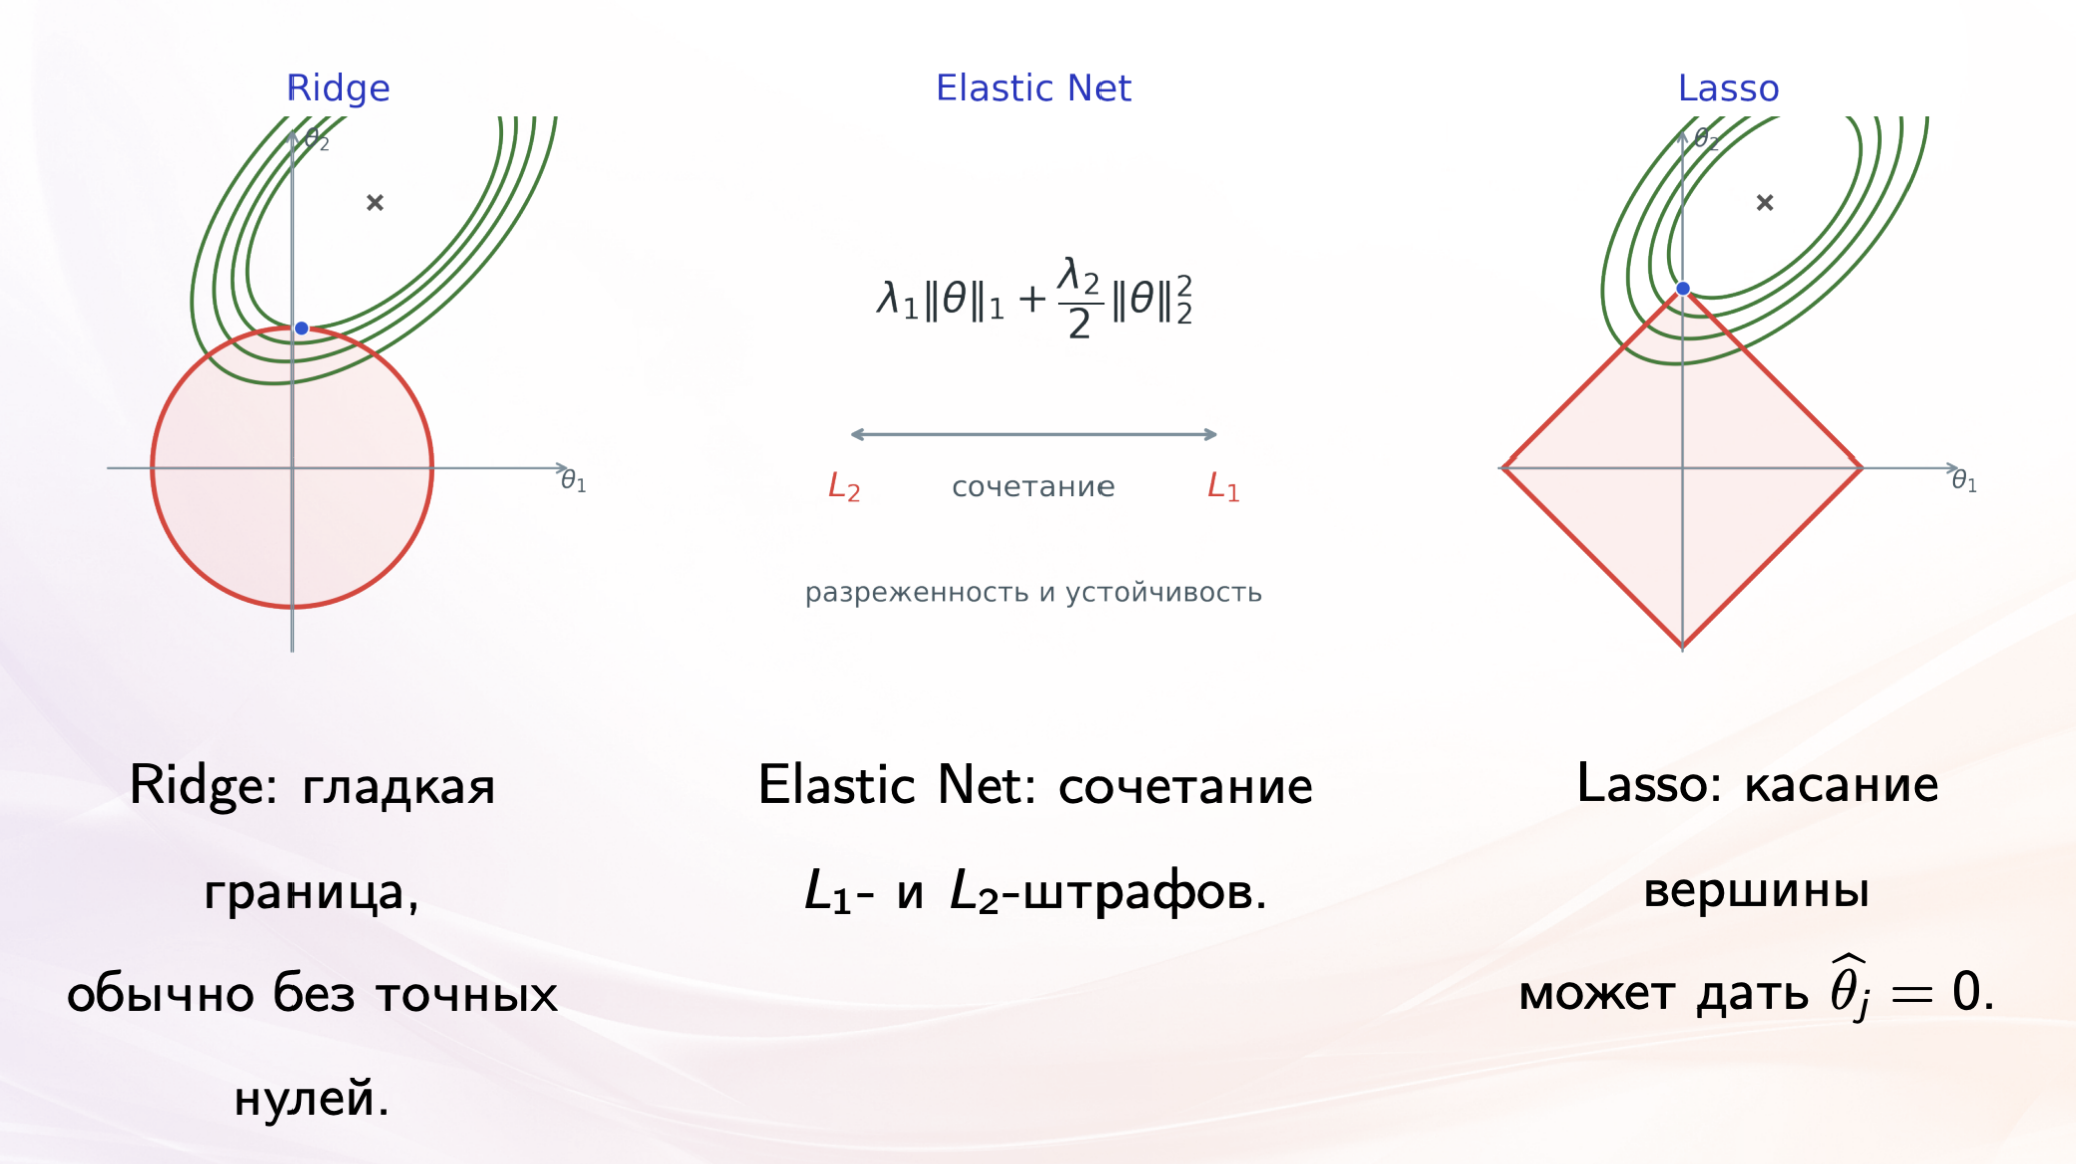

Сделаем то же самое для ElasticNet

Ограничения для двумерной минимизации ElasticNet выглядит так (ограниченная форма задачи минимизации):

Пусть $(\theta_1, \theta_2)^T = \theta$ - признаки

Тогда ограничения: L1_norm + L2_norm < a, a = const

$|\theta_1| + |\theta_2| + \theta_1^2 + \theta_2^2 < a$

Я построила их в десмосе и вот что вышло

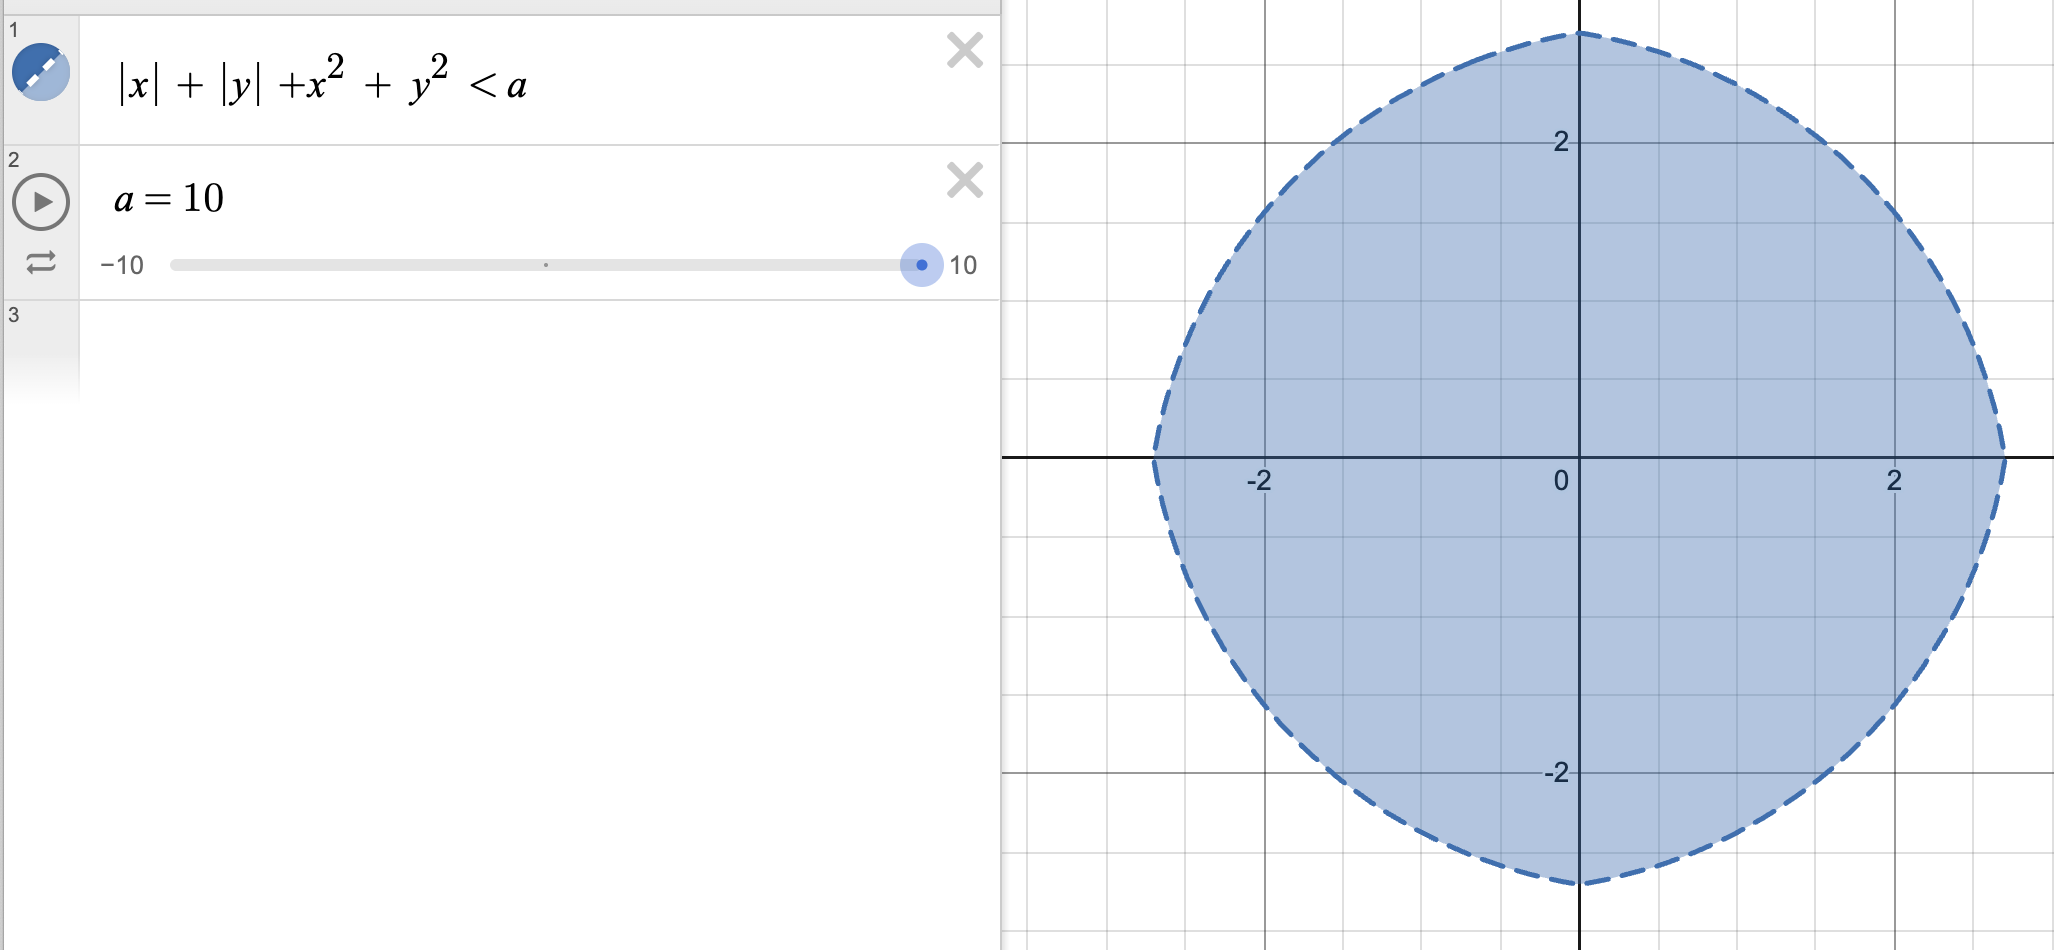

Получился ромбовидный кружочек, помесь кружочка + ромбика, поскольку есть и L1, и L2-регуляризации

Вот как это выглядит при разных a:

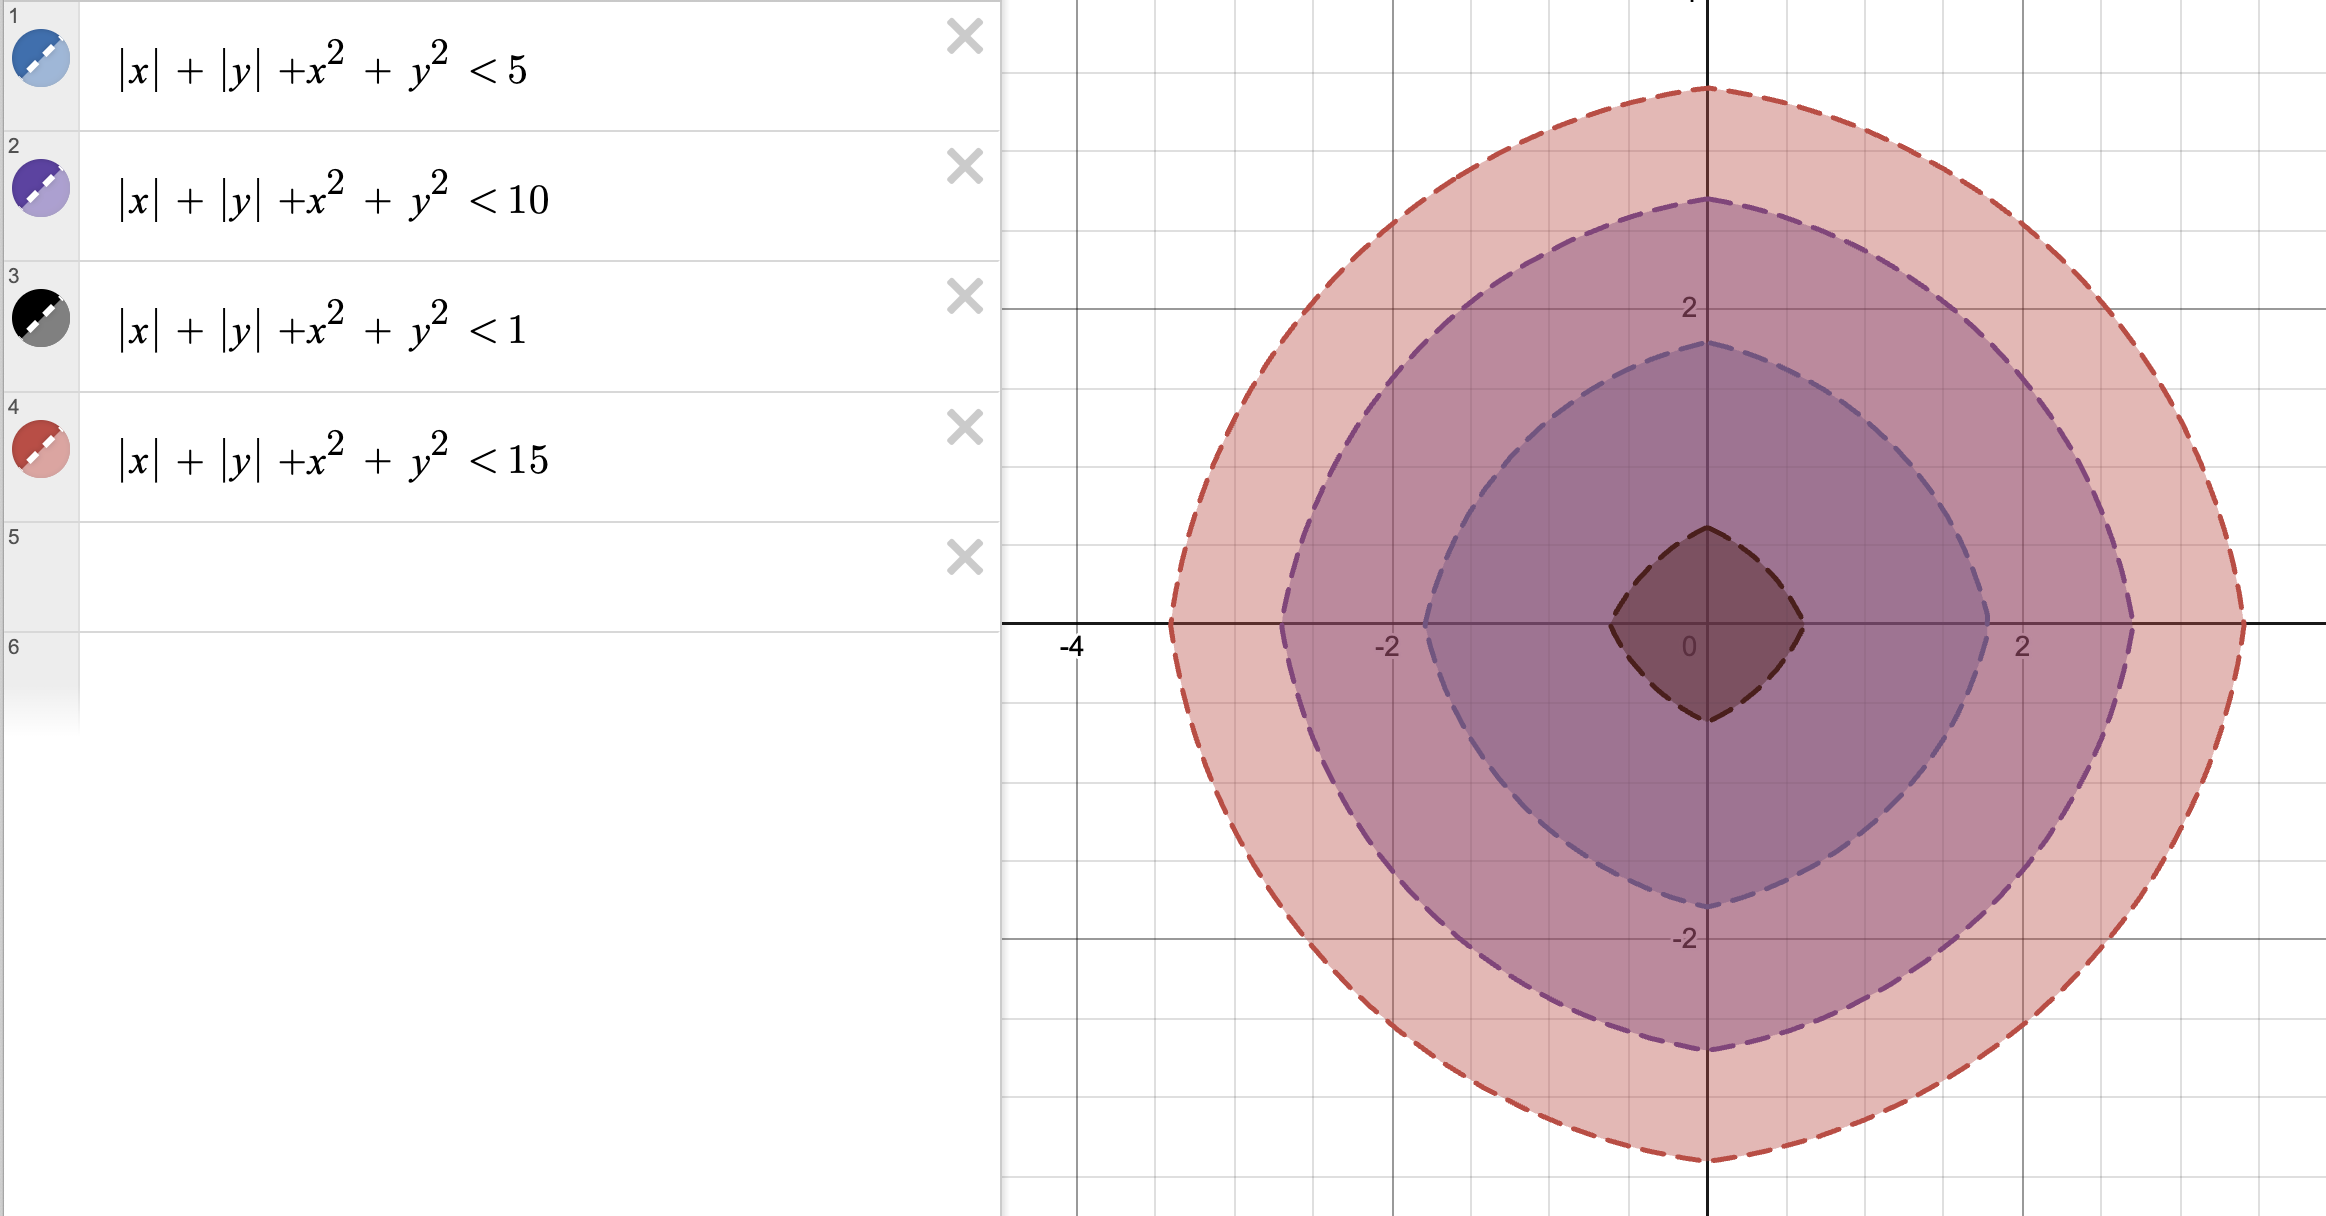

* При маленьких a, ограничения по форме напоминают ромб, но с кругленный чуть-чуть

* При больших a, по форме ограничения больше напоминают круг, но с слегка проступающими уголками как у ромба

**2.** Выведите итерационную формулу пересчета коэффициентов модели с помощью формулы решения через проксимальный оператор.

Какой вы можете видеть эффект при изменении параметра регуляризации и в чем
его отличие от лассо-регрессии?

Снова рассмотрим основную задачу $\min\limits_{\theta} \Phi(\theta) = F(\theta) + \lambda R(\theta)$, где:

* $F(\theta) = \text{MSE} = ||y - X \theta||_2^2$ в качестве основного лосса взяли MSE
* $R(\theta) = \text{L2-норма весов} = \lambda_1 * ||\theta||_1 + \lambda_2 * ||\theta||_2^2$ в качестве регуляризации взяли ElasticNet

В этом случае мы как в первой задаче не обойдем простым градиентным методом оптимизации, поскольку у нас в регуляризации фигурирует 1-норма вектора весов, а 1-норм - не диффиренцируема в нуле, из-за чего сейчас нам придется поработать с субградиентом и проксимальным оператором:

**Вспомним определение:** для выпуклой функции $f$ (неоьязательно гладкой, как в нашем случае) определен проксимальный оператор

$\text{Pr}_f(p) = arg \min\limits_{x} (\frac{1}{2} \cdot ||x - p||_2^2 + f(x))$

**Условие оптимальности (того, что точка $x_0$ является минимумом):**

$x_0 = \text{Pr}_f(p) \Longleftrightarrow 0 \in x_0 - p + \partial f(x_0)$, просто взяли производную из определения выше

**Итерация проксимального градиента для основной задачи:**

1) Input: входные данные и инициализация параметров $\alpha, \lambda_1, \lambda_2$
2) пересчет весов как через обычный GD: $\theta_t - \alpha \nabla F(\theta_t)$
3) Навешивание на это все проксимального оператора (для эффекта регуляризации)

Общая формула:
$\theta_{t + 1} = \text{Pr}_{\alpha \lambda R}(\theta_t - \alpha \nabla F(\theta_t))$

**Работаем с нашими функциями**

* $F(\theta) = \text{MSE} = ||y - X \theta||_2^2$ в качестве основного лосса взяли MSE
* $R(\theta) = \text{L2-норма весов} = \lambda_1 * ||\theta||_1 + \lambda_2 * ||\theta||_2^2$ в качестве регуляризации взяли ElasticNet

1) градиент для $F = $ MSE известен с лекции, $\nabla_{\theta} F = 2 X^T (X\theta - y)$
2) можно делать шаг как в GD: $\theta_t - \alpha \nabla F(\theta_t) = \theta_t - \alpha 2 X^T (X\theta_t - y)$
3) Разберемся с проксимальным оператором для функции $\alpha R(\theta) = \alpha \lambda_1 * ||\theta||_1 + \alpha \lambda_2 * ||\theta||_2^2$

$\text{Pr}_{\alpha R}(p) = arg \min\limits_{x} (\frac{1}{2} \cdot ||x - p||_2^2 + \alpha \lambda_1 * ||x||_1 + \alpha \lambda_2 * ||x||_2^2)$

Надо минимум найти $x^{*}$ = arg min, поскольку под знаком arg min, обе функции выпуклые, но одна из них негладкая, то вместо обычной производной появится еще субградиент, и скажем что этому всему принадлежит ноль.

Пусть $A = ||x - p||_2^2 \Longrightarrow \nabla_{x} A = 2 (x - p)$, $B = ||x||_2^2 \Longrightarrow \nabla_{x} B = 2 x$

Тогда вся производная $0 \in x - p + 2 \alpha \lambda_2  x + \alpha \lambda_1 \partial{||x||_1}$

Рассмотрим покоординатно, $\forall i = 1...n$, ведь чтобы "минимизировать сам вектор", достаточно минимизировать каждую координату:

$0 \in x_i - p_i + 2 \alpha \lambda_2  x_i + \alpha \lambda_1 \partial{|x_i|} \Longleftrightarrow p_i - (x_i + 2 \alpha \lambda_2 x_i) \in \alpha \lambda_1 \partial{|x_i|} \Longleftrightarrow \frac{p_i}{1 + 2 \alpha \lambda_2} - x_i \in \frac{\alpha \lambda_1 \partial{|x_i|}}{1 + 2 \alpha \lambda_2}$

по критерию условия оптимальности о котором мы говорили выше, получаем:

$\Longleftrightarrow x_i = \text{Pr}_{\frac{\alpha \lambda_1}{(1 + 2\alpha \lambda_2)} | \cdot |}(\frac{p_i}{(1 + 2\alpha \lambda_2)}) = arg \min\limits_{x_i} (\frac{1}{2} \cdot (x_i - \frac{p_i}{(1 + 2\alpha \lambda_2)})^2 + \frac{\alpha \lambda_1}{(1 + 2\alpha \lambda_2)} |x_i|) =$

Из лекции мы знаем как считать такой проксимальный оператор:

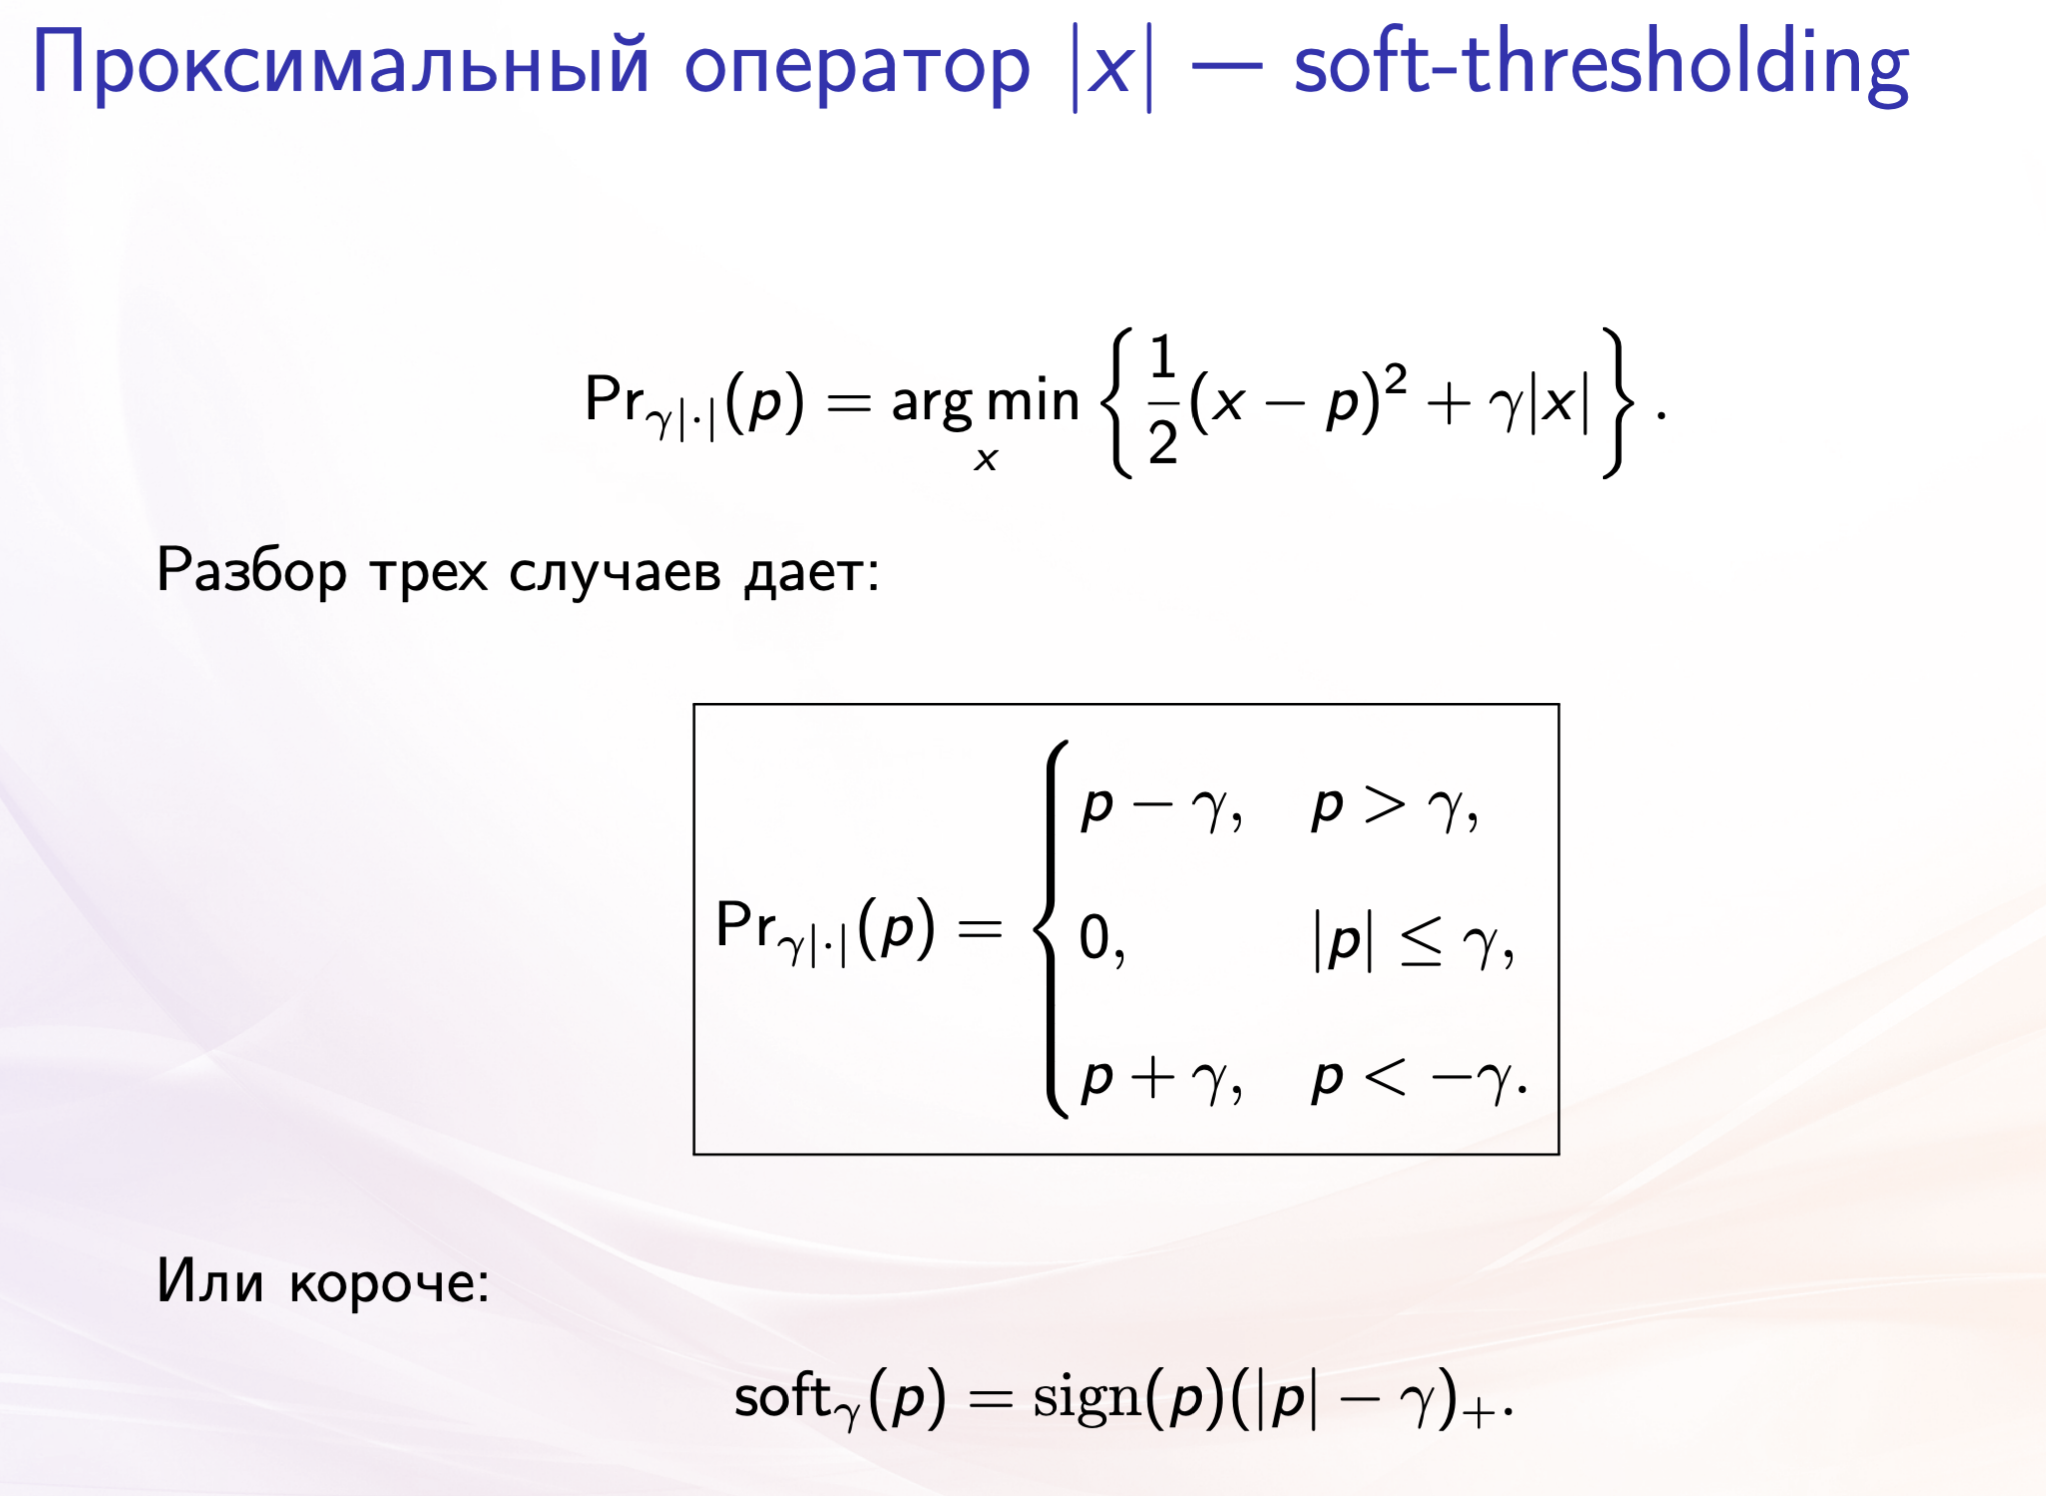

$ = \text{soft}_{\frac{\alpha \lambda_1}{(1 + 2\alpha \lambda_2)}}(\frac{p_i}{(1 + 2\alpha \lambda_2)}) = \text{sign}(\frac{p_i}{(1 + 2\alpha \lambda_2)}) \max(0, |\frac{p_i}{(1 + 2\alpha \lambda_2)}| - \frac{\alpha \lambda_1}{(1 + 2\alpha \lambda_2)}) = $

Так как по определению $\alpha > 0$ и $\lambda_2 > 0$, то:

$= \text{sign}(p_i) \max(0, |\frac{p_i}{(1 + 2\alpha \lambda_2)}| - \frac{\alpha \lambda_1}{(1 + 2\alpha \lambda_2)})$


4) Итоговая итерационная формула пересчета коэффициентов модели с помощью проксимального оператора

Пусть $p_t = \theta_t - 2 \alpha X^T (X\theta - y)$
$[\theta_{t + 1}]_i = \text{Pr}_{\alpha R}(\theta_t - \alpha \nabla_{\theta} F) =  \text{Pr}_{\alpha R}([\theta_t - 2 \alpha X^T (X\theta - y)]_i) = \text{Pr}_{\alpha R}([p_t]_i) = \text{sign}([p_t]_i) \max(0, |\frac{[p_t]_i}{(1 + 2\alpha \lambda_2)}| - \frac{\alpha \lambda_1}{(1 + 2\alpha \lambda_2)})$

Итак, $[\theta_{t + 1}]_i = \frac{1}{(1 + 2\alpha \lambda_2)}\text{sign}([p_t]_i) \max(0, |[p_t]_i|- \alpha \lambda_1)$, просто вынесли положительную константу за знак max

и так для каждой координаты

5) Замечание

Отмечу красивый факт: в задаче 1 мы посчитали как действует проксимальный оператор для L2 - это как раз гомотетия с коэффициентом $\frac{1}{(1 + 2\alpha \lambda_2)}$, мы ее здесь и наблдюдаем, а затем умножаем на проксимальный оператор для L1: $\text{sign}([p_t]_i) \max(0, |[p_t]_i|- \alpha \lambda_1)$, то применяется и та регуляризация и та в ElasticNet

6) Какой вы можете видеть эффект при изменении параметра регуляризации и в чем
его отличие от лассо-регрессии?

* При $\lambda_1 \to +\infty: [\theta_{t + 1}]_i = \frac{1}{(1 + 2\alpha \lambda_2)}\text{sign}([p_t]_i) \max(0, |[p_t]_i|- \alpha \lambda_1) \to 0$, из за стоящего max, то есть веса все будут занулятся, прям становится нулями -- отбор признаков

* При $\lambda_2 \to +\infty: [\theta_{t + 1}]_i = \frac{1}{(1 + 2\alpha \lambda_2)}\text{sign}([p_t]_i) \max(0, |[p_t]_i|- \alpha \lambda_1) \to 0$, из за того, что $\lambda_2$ в знаменателе, таким образом модель становится устойчивее и дисперсия весов при сильной мультиколлинеарности становится меньше.

* При $\lambda_1 = \lambda_2 = 0$, даже проксимальный оператор никакой не нужен это просто задача МНК

* В чем отличие от Lasso?

У Lasso есть классное свойство - отбирать признаки, и занулять веса неважных признаков. Но это же свойство - является и недостатком, так как есть неопределенность отбора. Пусть есть два признак дублирующих, один надо оставит, один убрать, вопрос: какой из двух будем убирать? непонятно, вероятность = $\frac{1}{2}$ убрать первый = вероятность убрать второй. Из-за этого при добавлении шума в данные Lasso может стать нестабальной и тут нам на помощь приходит L2-регуляризация, которая группирует коррелированные признаки, не выкидывая какой-то из признаков, а размазывая веса по этой группе признаков (в нашем примере - по двум признакам).

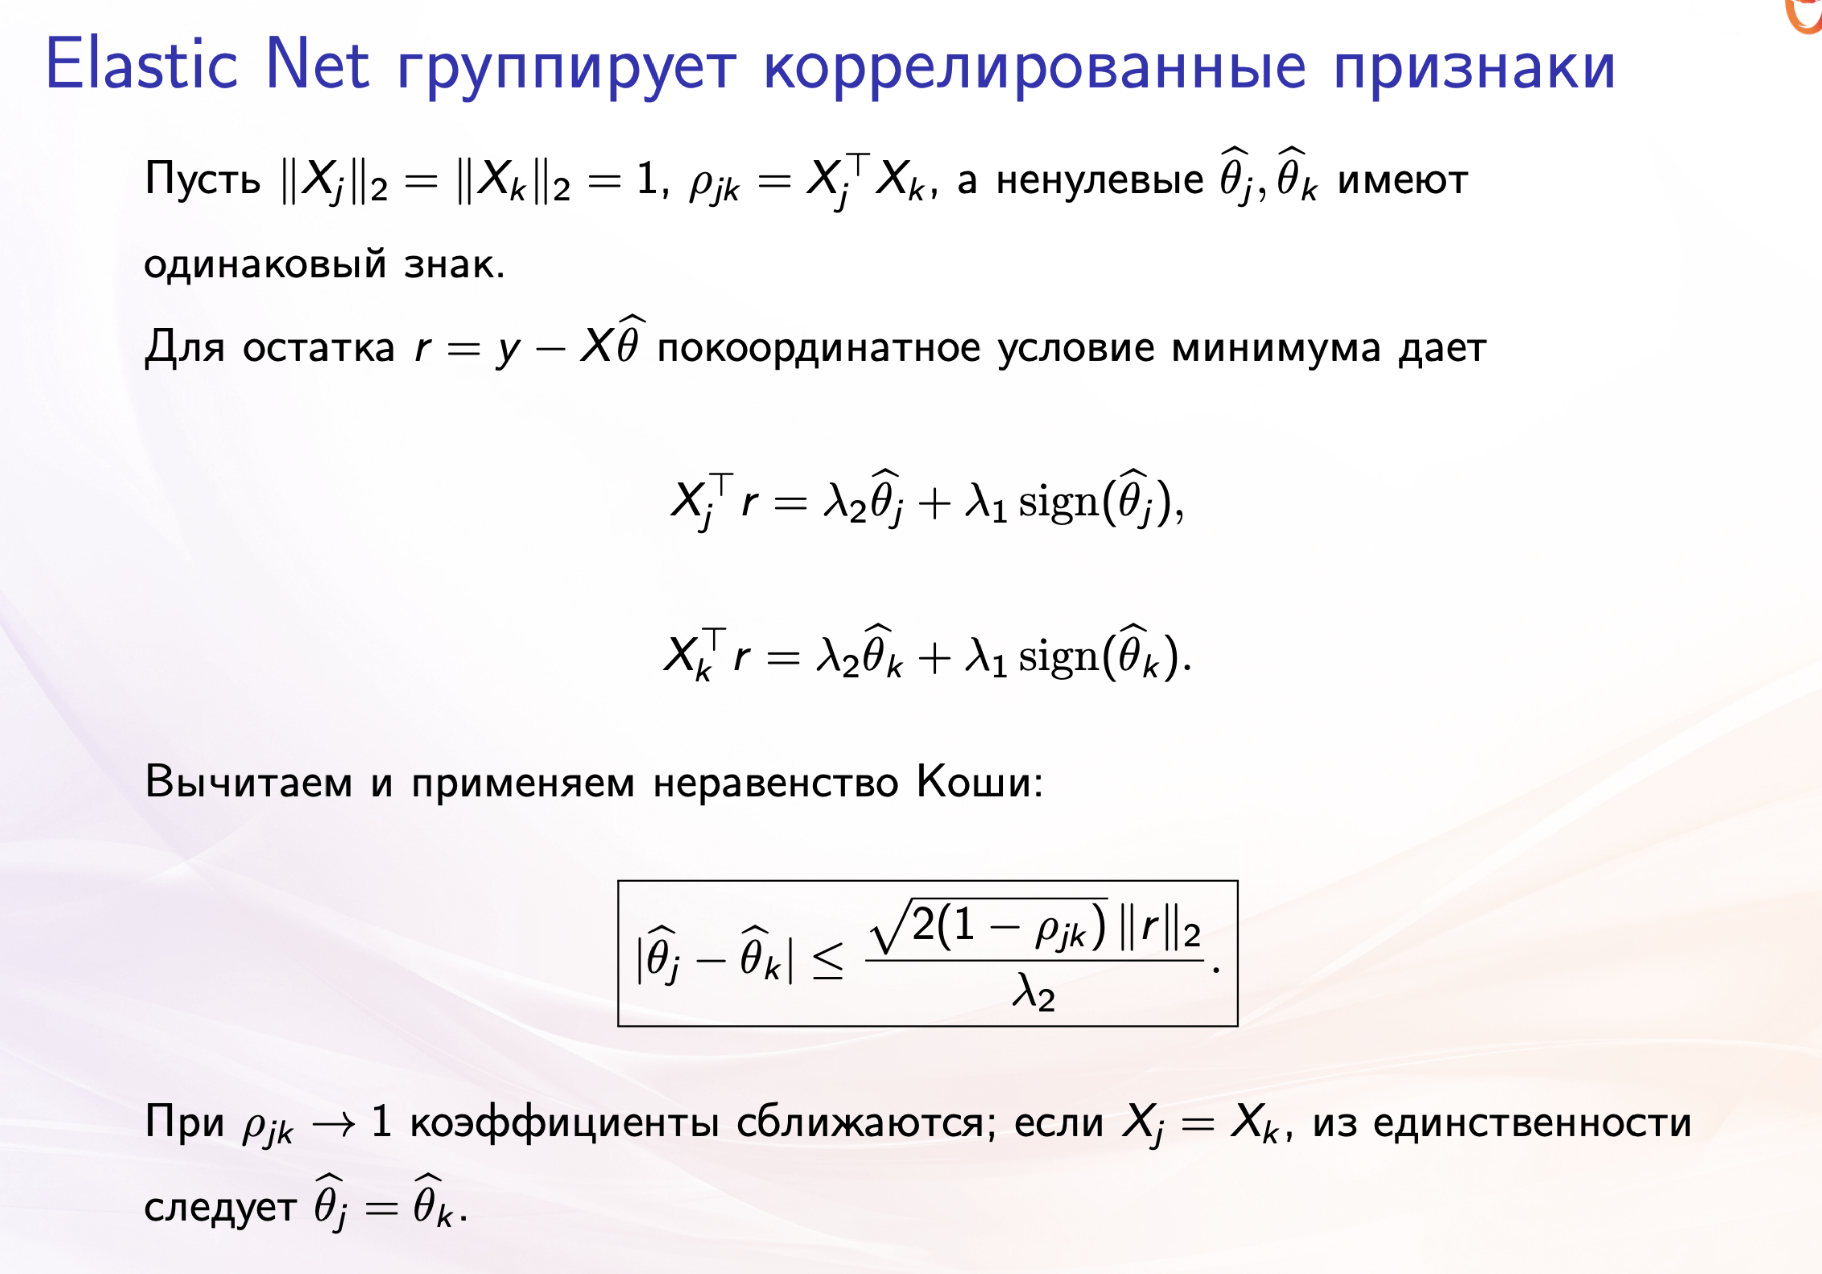


**3.** Выпишите формулы для градиентного и стохастического спуска.

Мы вывели вот такую формулу для пересчета весов для ElasticNet регуляризации и минимизации MSE:

Пусть $p_t = \theta_t - 2 \alpha X^T (X\theta_t - y)$

$[\theta_{t + 1}]_i = \frac{1}{(1 + 2\alpha \lambda_2)}\text{sign}([p_t]_i) \max(0, |[p_t]_i|- \alpha \lambda_1)$, для каждой координаты, теперь применим к векторам покомпонентно

**Градиентный спуск (GD)**

$\theta_{t + 1} = \frac{1}{(1 + 2\alpha \lambda_2)}\text{sign}(p_t) * \max(0, |p_t|- \alpha \lambda_1)$

где * - покомпонентное умножение векторов, то есть в numpy это бы выглядело так:

theta_{t + 1} = (np.sign(p_t) * np.maximum(0, np.abs(p_t) - alpha * lambda1)) / (1 + 2 * alpha * lambda2)


**Стохастический Градиентный спуск (SGD)**

Отличие SGD от GD - что мы веса пересчитваем не по всей выборке, а по батчу

$I_t$ - батч индексов объектов, сэмплированный случано с повторениями из равномерного распределения на всех индексах {$1, 2, ..., n$}

Пусть $p_{I_t} = \theta_t - \frac{2n}{|I_t|} \alpha X_{I_t}^T (X_{I_t}\theta_t - y_{I_t})$ как в обычном (не проксимальном градиентном спуске) отнормировали на размер батча, для несмещенности оценки направления антиградиента

$\theta_{t + 1} = \frac{1}{(1 + 2\alpha \lambda_2)}\text{sign}(p_{I_t}) * \max(0, |p_{I_t}|- \alpha \lambda_1)$


---
### Задача 3.

Рассмотрим модель логистической регрессии. Признаки объекта представимы в виде $d$-мерного вектора $x \in \mathbb{R}^d$, класс имеет бернулиевское распределение $Y \sim Bern(\mu_\theta(x))$. Мы делаем следующее предположение о зависимости параметра вероятности от признаков:
$${\mu_\theta(x) = \sigma(x^T\theta)= \cfrac{1}{1 + e^{-x^T\theta}}}.$$

Зададим регуляризацию через минимизацию следующего функционала:

$$F(\theta) = -\sum_{i=1}^n \left[Y_i \log{\sigma(\theta^T x_i)} + (1 - Y_i) \log{\left(1 - \sigma(\theta^T x_i)\right)}\right] + \lambda\theta^T \theta$$

**1.** Выведите формулы градиентного спуска (GD) и стохастического градиентного спуска (SGD).


**Общая формула переходов в GD / SGD**
$\theta_{t + 1} = \theta_t - \eta_t * \nabla F(\theta_t)$

Так что задачала свелась к подсчету градиента функции эмпирическиго риска $F(\theta)$

$x_i$ - это $i$ый объект $\in \mathbb{R}^n$, тогда $\theta^T * x_i$ - просто линейная комбинация всех признаков объекта $i$ с коэффициентами из вектора весов $\theta$

Пусть $z_i = \theta^T * x_i$, тогда $\frac{\partial z_{i}}{\partial \theta }=x_{i}$

Пусть $h_i = \sigma(z_i) = \sigma(\theta^T * x_i)$

Пусть $F(\theta) = L(\theta) + R(\theta)$

На введении в АД мы выводили, что $\frac{\partial \sigma(z)}{\partial z} = \sigma(z) * (1 - \sigma(z))$, где $z \in \mathbb{R}, \sigma(.)$ - это логистическая сигмоида и $\sigma(z) = \frac{1}{1 + e^{-z}}$

$$\nabla_{\theta} L(\theta) = -\sum_{i=1}^n (\frac{Y_i}{h_i} * \frac{\partial h_i}{\partial \theta} +  \frac{\partial Y_i}{\partial \theta} * \log(h_i)) + (\frac{1 - Y_i}{1 - h_i} * (-\frac{\partial h_i}{\partial \theta}) + \frac{\partial 1 - Y_i}{\partial \theta} * \log(1 - h_i)))$$

В силу того, что $\frac{\partial Y_i}{\partial \theta} = 0$ и $\frac{\partial 1 - Y_i}{\partial \theta} = 0$, так как $Y_i$ - константа

$$\nabla_{\theta} L(\theta) = -\sum_{i=1}^n (\frac{Y_i}{h_i} * \frac{\partial h_i}{\partial \theta}) + (\frac{1 - Y_i}{1 - h_i} * (-\frac{\partial h_i}{\partial \theta}))$$

Так как $h_i = \sigma(\theta^T * x_i) = \sigma(z_i)$, то $\frac{\partial h_i}{\partial \theta} = \frac{\partial h_i}{\partial z_i} * \frac{\partial z_i}{\theta}$, мы все это выше посчитали уже, теперь подставляя получим: $\frac{\partial h_i}{\partial \theta} = h_i * (1 - h_i) * x_i$

Тогда имеем:

$$\nabla_{\theta} L(\theta) = -\sum_{i=1}^n (\frac{Y_i}{h_i} * h_i * (1 - h_i) * x_i + (\frac{1 - Y_i}{1 - h_i} * (-h_i * (1 - h_i) * x_i)) = -\sum_{i = 1}^n (\frac{Y_i}{h_i} - \frac{1 - Y_i}{1 - h_i}) * h_i * (1 - h_i) * x_i$$

приводим к общему знаменателю

$$\nabla_{\theta} L(\theta) = -\sum_{i = 1}^n (\frac{Y_i * (1 - h_i) - (1 - Y_i) * h_i}{h_i * (1 - h_i)}) * h_i * (1 - h_i) * x_i = \sum_{i = 1}^n (h_i - Y_i) * x_i$$

Итого, получаем: $\nabla_{\theta} L(\theta) = \sum_{i = 1}^n (\sigma(\theta^T * x_i) - Y_i) * x_i$

2. Работаем с членом регуляризации $R(\theta) = \lambda\theta^T \theta$

$R(\theta) = \lambda\theta^T \theta = \lambda \sum_{i = 1}^d \theta_i^2$

Отсюда, понятно, что производная по каждой компоненте $\theta_j$ есть $2 \cdot \lambda \cdot \theta_j$

тогда $\nabla_{\theta} R(\theta) = 2 \cdot \lambda \cdot \theta$

3. Итоговый градиент $\nabla_{\theta} F(\theta) = \nabla_{\theta} L(\theta) + \nabla_{\theta} R(\theta)$

$\nabla_{\theta} F(\theta) = \sum_{i = 1}^n (\sigma(\theta^T * x_i) - Y_i) * x_i + 2 \cdot \lambda \cdot \theta$

**Градиентный спуск (GD) по всем объектам**

$\theta_{t + 1} = \theta_t - \eta_t * (\sum_{i = 1}^n (\sigma(\theta_t^T * x_i) - Y_i) * x_i + 2 \cdot \lambda \cdot \theta_t)$


**Стохастический градиентный спуск (SGD) по батчам**

$\theta_{t + 1} = \theta_t - \eta_t * g_{I_t}$, где:

$g_{I_t} = \frac{2n}{|I_{t}|} \cdot (\sum_{i \in I_t} (\sigma(\theta_t^T * x_i) - Y_i) * x_i) + 2 \cdot \lambda \cdot \theta_t$

ВАЖНО: как на лекции градиент регуляризации отдельно!!!

$I_t$ - батч индексов объектов, сэмплированный случано с повторениями из равномерного распределения на всех индексах {$1, 2, ..., n$}



**2.** Покажите, что $F(\theta)$ &mdash; выпуклая функция по $\theta$ и, как следствие, имеет единственный экстремум, являющийся глобальным максимумом. *Указание*. Посчитайте гессиан (матрицу вторых производных) и покажите, что она положительно определена.



**Доказательство выпуклости функции $F(\theta)$**

Пусть $z_i = \theta^T x_i$, а $h_i = \sigma(z_i) = \sigma(\theta^T x_i)$

Производную сигмоиды мы только что считали: $\frac{\partial \sigma(z_i)}{\partial \theta} = \sigma(z_i) * (1 - \sigma(z_i)) * x_i^T = h_i * (1 - h_i) * x_i^T$.

Используем то, что мы знаем первый градиент:
$\nabla_{\theta} F(\theta) = \sum_{i = 1}^n (\sigma(\theta^T x_i) - Y_i) * x_i + 2 \cdot \lambda \cdot \theta$

Чтобы посчитать Гессиан продифференцируем еще раз:
$$\nabla^2_{\theta} F(\theta) = \frac{\partial}{\partial \theta} \left( \sum_{i = 1}^n (\sigma(\theta^T x_i) - Y_i) * x_i + 2 \cdot \lambda \cdot \theta \right)$$

В силу того что $Y_i$ - константа, получаем:
$$\nabla^2_{\theta} F(\theta) = \sum_{i = 1}^n \frac{\partial \sigma(\theta^T x_i)}{\partial \theta} * x_i + 2 \cdot \lambda \cdot I = \sum_{i = 1}^n \sigma(\theta^T x_i) * (1 - \sigma(\theta^T x_i)) * x_i * x_i^T + 2 \cdot \lambda \cdot I$$
где $I$ — единичная матрица

**Доказательство положительной определенности Гессиана по определению**

Пусть $u \in \mathbb{R}^n$ - произвольный ненулевой вектор. Умножим Гессиан на $u^T$ слева и на $u$ справа и посмотрим на знак:
$$u^T * \nabla^2_{\theta} F(\theta) * u = u^T * \left( \sum_{i = 1}^n \sigma(\theta^T x_i) * (1 - \sigma(\theta^T x_i)) * x_i * x_i^T + 2 \cdot \lambda \cdot I \right) * u$$

Раскрываем скобки:
$$u^T * \nabla^2_{\theta} F(\theta) * u = \sum_{i = 1}^n \sigma(\theta^T x_i) * (1 - \sigma(\theta^T x_i)) * (u^T * x_i) * (x_i^T * u) + 2 \cdot \lambda \cdot (u^T * I * u)$$

Так как $(u^T * x_i) * (x_i^T * u) = (u^T * x_i)^2$, а $u^T * I * u = ||u||_2^2$, то имеем:
$$u^T * \nabla^2_{\theta} F(\theta) * u = \sum_{i = 1}^n \sigma(\theta^T x_i) * (1 - \sigma(\theta^T x_i)) * (u^T * x_i)^2 + 2 \cdot \lambda \cdot \|u\|^2$$

Мы знаем, что:
1. $(u^T * x_i)^2 \ge 0$
2. $\lambda > 0$ по опр коэффициента регуляризации
3. $\sigma(\theta^T x_i) * (1 - \sigma(\theta^T x_i)) > 0$ всегда по свойству сигмоиды, так как $\sigma(\theta^T * x_i) = \frac{1}{1 + e^{-\theta^T * x_i}} \in (0, 1)$
4. $\|u\|^2 > 0$ так как вектор $u \neq 0$

А значит вся сумма, то есть $u^T * \nabla^2_{\theta} F(\theta) * u > 0$, что по определению значит, что Гессиан строго положительно определен. Значит как мы знаем из матана $F(\theta)$ является строго выпуклой и имеет единственный глобальный экстремум, являющийся глобальным минимумом (так как мы минимизируем $F$)

**3.** Опишите, как может вести себя решение при отсутствии регуляризации, то есть при $\lambda = 0$

1. Геометрическая идея логистической регрессии для задачи классификации (как Задача 4, без ограничения общности бинарная классификация)
Вообще, логистическая регресиия - это просто линейная регресиия, на которую накинули сигмоиду - казалось бы нелинейная фнукция, может она нелинейно разделяет классы объектов? Но нет.

Была линейная регресиия: $y = \theta^T * x$ -- это линейное уравнение гиперплоскости

Мы хотим классифицировать наши точки

Понятно, что чем дальше точка находится от гиперплоскости тем больше модель уверена к какому классу ее отнести, то есть модель лин регресии по факту предсказала расстояние от гиперплоскости. А с помощью сигмоиды (получит лог регресиия) мы переведем это расстояние в вероятность: если расстояние большое до гиперплоскости (то взависимости от того с какой стороны от гиперплоскости находится точка), то вероятность пинадлжености к какому-то классу будет большая, так как модель сильно уверена в том к какому классу ее отнести (то есть либо $p_1 - $ вероятность точке буть из первого класса или $1 - p_1 = p_0$ будет большое)

2. Продолжая тему геометрии посмотрим на то, как мы минимизируем нашу функцию эмпирического риска = Loss + 0 * Regularization

Заметим, что $\nabla^2_{\theta} F(\theta) = \sum_{i = 1}^n \sigma(\theta^T x_i) * (1 - \sigma(\theta^T x_i)) * x_i * x_i^T = X * \Sigma * X^T$, где $\Sigma = \text{diag}(\sigma(\theta^T x_i) * (1 - \sigma(\theta^T x_i)))_{i = 1}^n$

За что отвечает вторая производная: за выпуклость / вогнутость. Если $F'' = 0 \Longrightarrow \int F'' = F' = c \in \mathbb{R} \Longrightarrow F = \int F' = cx + c_2$, то есть исходная фнукция линейная; вот и здесь в многомерном случае с нашей функцией эмпирического риска так же: если у нее Гессиан - почти нулевая марица, то гиперповерхность - выраждается в гиперплоскость, а на гиперплоскости можно очень долго идти до минимума и так к нему и не прийти, потому что его там нет.

3. При чем тут мультиколинеарность?

Мультиколлинеарность означает линейную зависимость признаков $\Longleftrightarrow \det(X^T * X) = 0 \Longleftrightarrow \lambda_{\text{min}}(X) = 0 \Longleftrightarrow$ есть сингулярные числа нулевые или около нулевые. Здесь везде равенство нулю понимается как или в точности ноль, или околонулевое значение.

Если есть мультиколлинеарность $\Longrightarrow \det(X^T * X) = 0 \Longrightarrow \nabla^2_{\theta} F(\theta) = X * \Sigma * X^T \approx 0$, так как $\Sigma$ - просто делает гомотетию, но линейная зависимость, которая есть в $X * X^T$ никуда при этом не девается. Итак, получается, что при мультиколлинеарности наша многомерная функция $F(\theta)$ задающая гиперповерхность может выродится в линейную гиперплоскость, а у нее минимума нет у гиперплоскости -- и всё, даже если мы как-то отыщем этот якобы min (с помощью max_iter в SGD), он будет неверным и веса модели будут непойми какими

4. Что происходит с весами модели?

Задача модели - оптимизационная: минимизировать функцию эмпирического риска, она выглядит так:

$$F(\theta) = -\sum_{i=1}^n \left[Y_i \log{\sigma(\theta^T x_i)} + (1 - Y_i) \log{\left(1 - \sigma(\theta^T x_i)\right)}\right] \to $$ min

Мы знаем, что $\sigma(\theta^T * x_i) = \frac{1}{1 + e^{-\theta^T * x_i}}$

$F$ будет минимальна при $\sigma(\theta^T * x_i) \to 1$ на тех объектах, где $x_i$ действительно принадлежит к классу 1

$\sigma(\theta^T * x_i) \to 0$ на тех объектах, где $x_i$ действительно принадлежит к классу 0

для этого $\theta^T * x_i \to +\infty \Longrightarrow \sigma(\theta^T * x_i) \to 1$,

для этого $\theta^T * x_i \to -\infty \Longrightarrow \sigma(\theta^T * x_i) \to 0$

То есть без регуляризации, модель будет стремится сделать веса большими по модулю, чтобы $\theta^T * x_i \to \infty$ и чтобы как следствие минимизировать $F(\theta)$

Особенно, если есть мультиколлинеарность, веса для коллинеарные признаков будут утягивать по разные стороны, а значения большие по модулю

---
### Задача 4.


**Введение**

Рассмотрим обезличенные [данные](https://www.kaggle.com/datasets/juice0lover/users-vs-bots-classification) о профилях пользователей ВК. Здесь собрана информация почти о 6 тыс. аккаунтах. Часть из них принадлежит реальным людям, а часть &mdash; боты. В этой задаче вы увидите, как регуляризация влияет на интерпретацию коэффициентов модели логистической регрессии.

**Описание датасета**

Данные содержат 60 столбцов. Столбец `target` &mdash; метка целевого класса (бот/пользователь). Признаки можно условно разбить на несколько групп:

1. Числовые признаки:
    -   Метрики активности (среднее кол-во постов за неделю)
    -   Количество друзей/подписчиков
2. Категориальные признаки:
    -   Атрибуты профиля (установлен ли аватар, указан ли номер телефона)
    -   Город
    -   Настройки приватности (закрытый/открытый профиль)
    -   Различные бинарные флаги (можно ли писать в личные сообщения)

**1.** **Загрузка и подготовка данных**

Загрузите датасет, выведите его размер и описание числовых фичей при помощи метода `describe`. Отличается ли масштаб у числовых признаков?

In [3]:
data_frame = pd.read_csv("bots_vs_users.csv")

print(f"Кол-во колонок: {data_frame.shape[0]}\n"
      f"Кол-во признаков: {data_frame.shape[1]}")

data_frame.describe()

Кол-во колонок: 5874
Кол-во признаков: 60


,target,posts_count,avg_likes,links_ratio,hashtags_ratio,avg_keywords,avg_text_length,attachments_ratio,avg_comments,reposts_ratio,ads_ratio,avg_views,posting_frequency_days,phone_numbers_ratio,avg_text_uniqueness
count,5874.000000,1391.000000,1391.000000,1391.000000,1391.000000,1391.000000,1391.000000,1391.000000,1391.000000,1391.000000,1391.000000,1391.000000,1391.000000,1391.000000,1391.000000
mean,0.500000,18.629044,19.552487,0.156463,0.143918,7.730661,544.752035,0.895945,0.610812,0.433638,0.002667,623.834788,66.330065,0.000568,0.668009
std,0.500043,4.231994,41.954881,0.202730,0.187085,11.278711,746.728130,0.170084,2.461709,0.397830,0.033136,1617.635460,154.970296,0.009545,0.229815
min,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,20.000000,0.400000,0.000000,0.000000,1.100000,86.600000,0.850000,0.000000,0.050000,0.000000,9.125000,1.980000,0.000000,0.580000
50%,0.500000,20.000000,7.600000,0.100000,0.050000,3.400000,267.800000,0.950000,0.000000,0.300000,0.000000,268.950000,30.950000,0.000000,0.710000
75%,1.000000,20.000000,26.075000,0.200000,0.200000,7.850000,616.850000,1.000000,0.200000,0.900000,0.000000,746.050000,89.480000,0.000000,0.830000
max,1.000000,20.000000,894.900000,1.000000,1.000000,61.600000,5841.250000,1.000000,64.050000,1.000000,0.950000,41415.700000,2866.590000,0.300000,1.000000


FUN FACT: Метод df.describe() по умолчанию выводит статистику только для числовых столбцов (целые числа и числа с плавающей точкой), пропуская текстовые и категориальные данные, оно и понятно, ведь describe выводит статистики (min, max, avg...) а их никак не посчитать на текстовых данных

In [4]:
data_frame.info()

<class 'pandas.DataFrame'>
RangeIndex: 5874 entries, 0 to 5873
Data columns (total 60 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   has_domain                  5874 non-null   str    
 1   has_birth_date              5874 non-null   str    
 2   has_photo                   5874 non-null   str    
 3   can_post_on_wall            5874 non-null   str    
 4   can_send_message            5874 non-null   str    
 5   has_website                 5874 non-null   str    
 6   gender                      5874 non-null   str    
 7   has_short_name              5874 non-null   str    
 8   has_first_name              5874 non-null   str    
 9   has_last_name               5874 non-null   str    
 10  access_to_closed_profile    5874 non-null   str    
 11  is_profile_closed           5874 non-null   str    
 12  target                      5874 non-null   int64  
 13  has_nickname                5874 non-null   

Выведем посмотреть первые пять строк

In [5]:
data_frame.head()

,has_domain,has_birth_date,has_photo,can_post_on_wall,can_send_message,has_website,gender,has_short_name,has_first_name,has_last_name,...,ads_ratio,avg_views,posting_frequency_days,phone_numbers_ratio,avg_text_uniqueness,city,has_occupation,occupation_type_university,occupation_type_work,has_personal_data
0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,...,NaN,NaN,NaN,NaN,NaN,Unknown,Unknown,Unknown,Unknown,Unknown
1,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,...,NaN,NaN,NaN,NaN,NaN,Unknown,Unknown,Unknown,Unknown,Unknown
2,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,...,NaN,NaN,NaN,NaN,NaN,Unknown,Unknown,Unknown,Unknown,Unknown
3,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,...,NaN,NaN,NaN,NaN,NaN,Unknown,Unknown,Unknown,Unknown,Unknown
4,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,...,NaN,NaN,NaN,NaN,NaN,Unknown,Unknown,Unknown,Unknown,Unknown


Отметим, что в колонке city есть значение Unknown

In [6]:
numeric_features = data_frame.drop(['target'], axis=1).select_dtypes(include=['number'])
print('Вещественные признаки:')
print(len(numeric_features.columns))
print(list(numeric_features.columns))

Вещественные признаки:
14
['posts_count', 'avg_likes', 'links_ratio', 'hashtags_ratio', 'avg_keywords', 'avg_text_length', 'attachments_ratio', 'avg_comments', 'reposts_ratio', 'ads_ratio', 'avg_views', 'posting_frequency_days', 'phone_numbers_ratio', 'avg_text_uniqueness']


**Ответ:** из вывода describe() видно, что в данных есть признаки разного масштаба:

- ads_ratio имеет mean = 0.0026
- links_ratio имеет mean = 0.15
- avg_text_length имеет mean = 544.75

разница колосальная и все признаки находятся в категории вещественных признаков ибо как мне кажется рассматривать масштаб для категориальных признаков не имеет смысла

Подсчитайте количество уникальных значений в столбце `city` и выведите 5 наиболее частых городов.

Всего уникальных значений в столбец city: 362
TOP 5 CITIES:
Saint Petersburg, Kostomuksha, Moscow, Petrozavodsk, Nizhny Novgorod


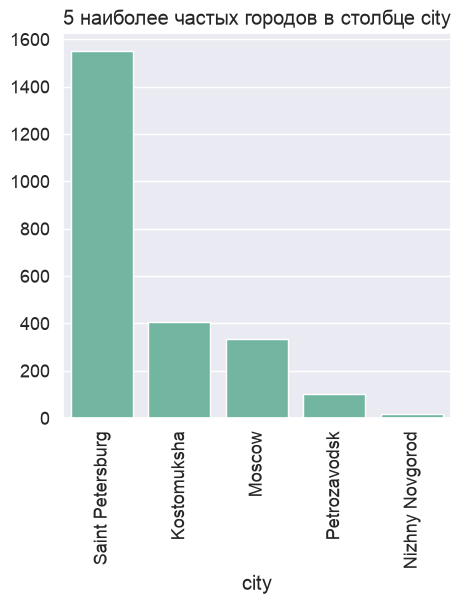

In [7]:
print(f"Всего уникальных значений в столбец city: {data_frame.city.nunique()}")

# Я увидела что в city есть значение Unknown, его я буду игнорировать и выведу именно 5 городов, Unknown - не город
print("TOP 5 CITIES:")
top5 = data_frame.city.value_counts(ascending=False)[1:6]
print(*list(top5.index), sep=", ", end="\n")

plt.figure(figsize=(5, 5))
sns.barplot(x=top5.index, y=top5.values)
plt.xticks(rotation=90)
plt.title("5 наиболее частых городов в столбце city")
plt.show()
# под индексом 0 находится Unknown

**Вывод:** В ВК больше пользователей из Москвы, Питера, Нижнего Новгорода - это крупные города с большим населением, у большинства из которого есть доступ в интеренет и в том числе к ВК,

Петрозаводск недалеко от Питера - там тоже люди используют ВК, хотя население относительно того же Питера или Москвы не очень большое, и там мало аккаунтов около 100, а в Нижнем еще меньше

Само название города, который указан в профиле, нам не особо важно. **Замените** этот признак на простой бинарный флаг: указан/отсутствует.

In [8]:
# 1. Посмотрим есть ли пропуски
misses = data_frame.city.isnull().sum()
print("Пропусков нет" if data_frame.city.isnull().sum() == 0 else f"Пропусков столько: {misses}")

# 2. Среди значений data_frame.city.unique() есть Unknown
# ПУСТЬ 0 - отсутсвует, 1 - наличиствует
data_frame.city = np.where(data_frame.city.astype(str).str.lower().str.strip() == 'unknown', 0, 1)

print(f"Проверка типов:\n {list(data_frame.city.unique())}")

Пропусков нет
Проверка типов:
 [np.int64(0), np.int64(1)]


Выделите целевую переменную и матрицу признаков, убрав из неё лишние столбцы:

Во-первых, выделим целевую переменную и удалим из X столбец таргета

In [9]:
print("Целевая перемнная:")
print(f"Ее название: target")
y = data_frame.target
print("Ее значения:", list(y.unique()))

X = data_frame.drop(["target"], axis=1) # axis = 1 стобец
X

Целевая перемнная:
Ее название: target
Ее значения: [np.int64(1), np.int64(0)]


,has_domain,has_birth_date,has_photo,can_post_on_wall,can_send_message,has_website,gender,has_short_name,has_first_name,has_last_name,...,ads_ratio,avg_views,posting_frequency_days,phone_numbers_ratio,avg_text_uniqueness,city,has_occupation,occupation_type_university,occupation_type_work,has_personal_data
0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,...,NaN,NaN,NaN,NaN,NaN,0,Unknown,Unknown,Unknown,Unknown
1,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,...,NaN,NaN,NaN,NaN,NaN,0,Unknown,Unknown,Unknown,Unknown
2,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,...,NaN,NaN,NaN,NaN,NaN,0,Unknown,Unknown,Unknown,Unknown
3,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,...,NaN,NaN,NaN,NaN,NaN,0,Unknown,Unknown,Unknown,Unknown
4,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,...,NaN,NaN,NaN,NaN,NaN,0,Unknown,Unknown,Unknown,Unknown
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5869,1.0,1.0,1.0,0.0,0.0,Unknown,2.0,1.0,1.0,1.0,...,NaN,NaN,NaN,NaN,NaN,1,1.0,0.0,1.0,Unknown
5870,1.0,Unknown,1.0,0.0,0.0,Unknown,1.0,1.0,1.0,1.0,...,NaN,NaN,NaN,NaN,NaN,1,1.0,1.0,0.0,Unknown
5871,1.0,1.0,0.0,0.0,0.0,1.0,2.0,1.0,1.0,1.0,...,NaN,NaN,NaN,NaN,NaN,1,1.0,1.0,0.0,Unknown
5872,1.0,1.0,1.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0,...,NaN,NaN,NaN,NaN,NaN,1,1.0,0.0,1.0,Unknown


Отмечу, что X - матрица объекты + признаки выделилась верно, ведь стало на 1 столбец меньше

### Во-вторых, удалим еще лишние столбцы из матрицы X, следую пайплайну поиска мультиколлинеарност, который я выделила для себя с лекции:

1) Ищем попарно коллинеарные признаки с помощью матрицы корреляций
2) Сделать SVD
посмотреть есть ли сингулярные числа в $\varepsilon$ окрестности нуля, если да, то сингулярные числа, которые по номеру соотвествуют конкретному признаку X, этот признак надо убрать так как он неинформативеню
3) Посчитать индекс обусловленности CI
* если CI $\in [10, 20]$, то необходимо принять во внимание другие пункты этого пайплайна
* если CI $> 30$, то точно есть мультиколлинеарность

4) посчитать VIF для каждого вещественного признака
* если $\text{VIF}_{j}$ сильно больше 1, то это признак того, что данный признак $j$ линейно зависити от каких-то из оставшихся признаков

#### 1. Матрица корреляций

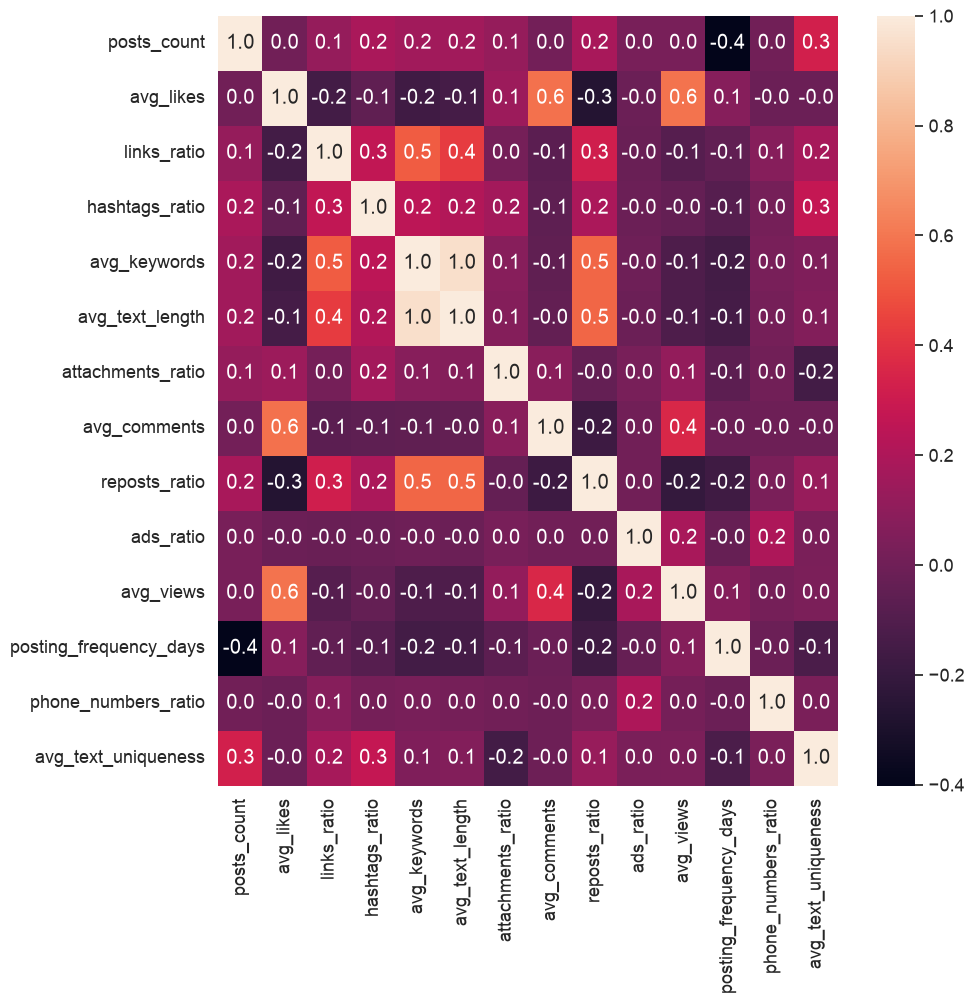

In [10]:
correlation_matrix = numeric_features.corr()
plt.figure(figsize=(10, 10))
sns.heatmap(correlation_matrix,
            annot=True, fmt=".1f") # добавить значения корреляций
plt.show()

Есть корреляция 1 не на диагонали, она у признаков -- (avg_text_length, avg_keywords) -- надо убрать один из них

Самая высокая корреляция двух признаков, кроме этого -- это 0.6, как мне кажется, это не повод удалять один из признаков в паре

In [11]:
X = X.drop(['avg_keywords'], axis=1)
# обновим наши вещественные категориальные фичи ибо мы только что поудаляли
numeric_features = X.select_dtypes(include=['number'])
cat_features = X.select_dtypes(include=["str", "category"])

#### 2. SVD в помощь (пока только на вещественных не Nan признаках)

In [12]:
# X = U * S * V^T, где S = diag(сингуляр числа)
# S - Vector containing the singular values sorted in descending order.

numeric_features_for_svd = numeric_features.copy().dropna()
# Для SVD нужна именно числовая матрица!
# категориальные признаки до кодировки не подойдут,
# вещественные признаки - да, ок, но только без Nan
# возможно после Pipeline который есть ниже в задании посмотрим еще раз на SVD, пока что первичный анализ
U, S, V_t = np.linalg.svd(numeric_features_for_svd, full_matrices=False)

print("Смотрим есть ли сингулярные числа принадлежащие окретсности 0")
print(S)
print("Пока что таких сингулярных чисел нет")

Смотрим есть ли сингулярные числа принадлежащие окретсности 0
[6.48696501e+04 3.40860147e+04 6.12956960e+03 1.30784210e+03
 4.98469555e+02 7.42056690e+01 1.50635058e+01 1.21298513e+01
 8.67463904e+00 8.30442222e+00 6.65912546e+00 6.03022149e+00
 1.20062333e+00 3.46632837e-01]
Пока что таких сингулярных чисел нет


#### 3. Считаем Conditional Index (CI) - Индекс обусловленности

In [13]:
# опять же, для счета CI нужна числовая матрица
ci = np.linalg.cond(numeric_features_for_svd)

print("Мультиколлинеарность есть!" if ci > 30 else "Все good, мультиколлинеарность несильная либо отсутсвует")

Мультиколлинеарность есть!


То есть несмотря на то, что мы удалили из одной пары (avg_text_length, avg_keywords), CI все равно большой, значит какие-то линейные зависимости в признаках все еще остались

Получили результат CI $> 30$, что жмпирически значит что мультиколлинеарность есть. Будем искать ее дальше, но уже после преобразований над категориальными признаками и заполнением Nan в вещественных признаках чем-то другим  или их удалением (решим позже). A пока...

#### Считаем VIF

$\text{VIF}_j$ считается только для вещественных признаков:

$\text{VIF}_j = \frac{1}{1 - R_j}$, где $R_j$ = доля информации признака $X_j$ которую могт объяснить все остальные признаки (делаем линейную регресиию на признак $X_j$ = target, если он вещественный, все остальные признаки выступают в этой задаче регрессии в качестве данных)

Поскольку мы делаем линейную регрессию на признак $j$, то она будет предсказывать вещественное число, значит признак $j$ тоже должен иметь вещественные значения, чтобы подсчет $\text{VIF}_j$ для него был осмысленным

Пока что в качестве всех остальных тоже буде брать только вещественные признаки (поскольку категориальные еще числами не закодированы)

In [14]:
from sklearn.metrics import r2_score
from sklearn.linear_model import LinearRegression

features_cnt = numeric_features.shape[1]
for j in range(features_cnt):
    if str(X.iloc[:, j].dtype) in ['float64', 'float32']:  # это вещественная фича
        col_name = numeric_features.columns[j]
        y_current = numeric_features.iloc[:, j] # в качестве таргета j-ый признак
        X_current = numeric_features.drop(col_name, axis=1)
        lr_model_j = LinearRegression()
        lr_model_j.fit(X_current, y_current)
        y_pred = lr_model_j.predict(X_current)

        r2 = r2_score(X[:, j], y_pred)
        vif = 1 / (1 - r2)
        if vif > 1:
            print(f"{j}-ый признак малоинформативен, его надо убрать, так как его с помощью лин регресии (лин зависимости) могут объяснить другие признаки")

Раз никто не вывелся в принте выше, это значит, что скорее всего зависимостей линейных в вещественных признаках нет. Нужно закодировать категориальные и попробовать еще раз этот код но уже для всего X, не для numeric_features - и посмотреть что получится.

#### В-третьих попробуем использовать подход с семинара

Теперь посчитаем пропуски в матрице X и нарисуем гистограмму

Text(0.5, 1.0, 'Распределение пропусков по индикаторам')

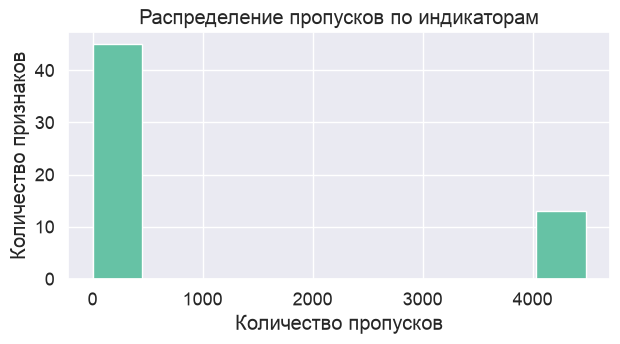

In [15]:
nans = X.isna().sum()
plt.figure(figsize=(7, 3.2))
nans.hist()
plt.xlabel("Количество пропусков")
plt.ylabel("Количество признаков")
plt.title("Распределение пропусков по индикаторам")

Понятно, что 4000 пропущенных значений никуда не годится - их придётся удалить. Зададим некоторый порог на допустимое число пропусков

In [16]:
# Задаём порог
threshold = 1000

# Удаляем
X.drop(columns=X.columns[nans > threshold], inplace=True)
print(
    f"Осталось {len(X.columns)} признаков с менее чем {threshold} пропущенными значениями"
)

# Обновляем numeric_features
numeric_features = X.select_dtypes(include=['number'])

Осталось 45 признаков с менее чем 1000 пропущенными значениями


Посчитайте количество нулей и единиц таргете. Лучше всего представить ответ в виде графика с двумя столбцами, высота которых соответствует количеству объектов класса (см. например, [`sns.countplot`](https://seaborn.pydata.org/generated/seaborn.countplot.html)). Есть ли дисбаланс между классами?

In [17]:
# Сначала напечатаю сколько их там
y.value_counts()

target
1    2937
0    2937
Name: count, dtype: int64

Ура, их одинаково, дисбаланса в классах нет. И правильно, у нас же тема урока мультиколлинеарность, а не как фиксить дисбаланс (хотя это тоже было бы интересно)

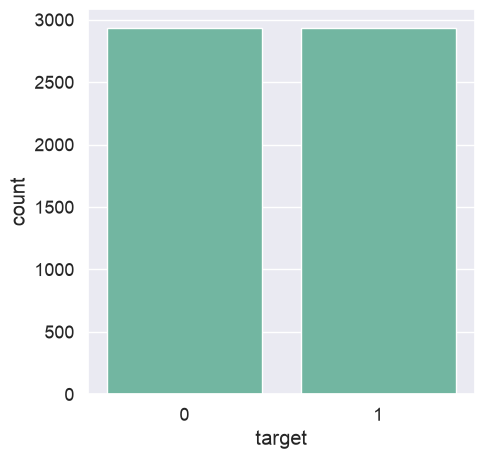

In [18]:
plt.figure(figsize=(5, 5))
sns.countplot(x=y)
plt.show()

**Ответ:** Дисбаланса в классах боты и пользователи нет

Разделите данные на трейн и тест. Аналогичным образом выведите распределение таргета по классам для обеих выборок. Соотношение классов в обучающей и тестовой частях должно быть одинаковым.

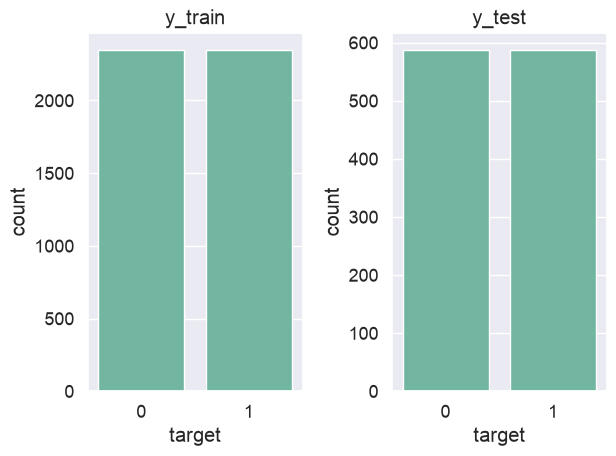

In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_SEED, stratify=y)
# stratify=y сохранить соотношение в тестовой и в обучающей как в исходном y, то есть и обуч выборке будет поровну 0, 1 и в test тоже будет поровну, то есть соотношение классов в обучающей и тестовой частях будет одинаковым.


fig, ax = plt.subplots(nrows=1, ncols=2)
sns.countplot(x=y_train, ax=ax[0])
ax[0].set_title("y_train")

sns.countplot(x=y_test, ax=ax[1])
ax[1].set_title("y_test")
plt.tight_layout()
plt.show()

**Ответ:** Видим что и там и там классы распределены поровну, только в обучающей выборке объектов больше, чем в тестовой

Согласно описанию на странице датасета, в данных есть пропуски. Причём в числовых признаках они отмечены значением `NaN`, а в категориальных &mdash; строкой `"Unknown"`. Удобнее сначала разобраться с категориальными. Примените к ним преобразование [OneHotEncoding](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html). При этом значения `"Unknown"` следует также распознавать как отдельную категорию.

In [20]:
from sklearn.preprocessing import OneHotEncoder

cat_features = X.select_dtypes(include=["str", "category"])

encoder = OneHotEncoder(sparse_output=False, drop='first') # чтобы возвращалась не разреженная матрица а numpy.array
# drop='first' - чтобы не было линейной зависимости
enc_res = encoder.fit_transform(X_train[cat_features.columns]) # надо только подматрицу с категориальным фичами передавать!!!
X_train_encoded = pd.DataFrame(
    enc_res,
    columns=encoder.get_feature_names_out(cat_features.columns),
    index=X_train.index
)

assert len(cat_features.columns) + len(numeric_features.columns) == X.shape[1]

Используя [`SimpleImputer`](https://scikit-learn.org/stable/modules/generated/sklearn.impute.SimpleImputer.html), заполните **числовые пропуски** средними значениями. Для каждого числового признака с пропусками создайте дополнительный признак-флаг, указывающий на наличие или отсутствие пропуска. Преобразуйте **только обучающую** выборку и убедитесь, что `NaN`-ов в ней действительно нет.

In [21]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy='mean', add_indicator=True)
X_train_filled = imputer.fit_transform(X_train[numeric_features.columns])
#  add_indicator=True - автоматически дополняет бинарным столбцом отсутсвуют / присуствуют пропуски

feature_names = imputer.get_feature_names_out(numeric_features.columns)
X_train_filled = pd.DataFrame(
    X_train_filled,
    columns=feature_names,
    index=X_train.index)

Стандартизируйте **числовые признаки** при помощи `StandardScaler`.

In [22]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_filled)

X_train_scaled = pd.DataFrame(
    X_train_scaled,
    columns=X_train_filled.columns,
    index=X_train.index)

После всех преобразований объединим X

In [23]:
X_train_final = pd.concat([X_train_scaled, X_train_encoded], axis=1)

Хорошо ли обусловлена преобразованная матрица $X$? О чём это говорит?

In [24]:
np.linalg.det(X_train_final.T @ X_train_final)

/Users/anna/PycharmProjects/ML2026/.venv/lib/python3.14/site-packages/numpy/linalg/_linalg.py:2406: RuntimeWarning: divide by zero encountered in det
  r = _umath_linalg.det(a, signature=signature)
/Users/anna/PycharmProjects/ML2026/.venv/lib/python3.14/site-packages/numpy/linalg/_linalg.py:2406: RuntimeWarning: overflow encountered in det
  r = _umath_linalg.det(a, signature=signature)
/Users/anna/PycharmProjects/ML2026/.venv/lib/python3.14/site-packages/numpy/linalg/_linalg.py:2406: RuntimeWarning: invalid value encountered in det
  r = _umath_linalg.det(a, signature=signature)


np.float64(0.0)

**Ответ:** Она ужасно обусловлена, определитель = 0! -- плохо обусловленная задача

Для наглядности, выведите матрицу корреляций. Что означают элементы матрицы? А в нашем случае?

In [25]:
c = X_train_final.corr()
c

,city,has_domain_Unknown,has_birth_date_Unknown,has_photo_1.0,has_photo_Unknown,can_post_on_wall_1.0,can_post_on_wall_Unknown,can_send_message_1.0,can_send_message_Unknown,has_website_1.0,...,is_confirmed_1.0,is_confirmed_Unknown,has_status_1.0,has_status_Unknown,has_occupation_Unknown,occupation_type_university_1.0,occupation_type_university_Unknown,occupation_type_work_1.0,occupation_type_work_Unknown,has_personal_data_Unknown
city,1.000000,-0.071676,0.138436,0.613981,-0.071676,0.141972,-0.071676,0.486754,-0.071676,0.312519,...,0.013960,-0.611185,0.349115,-0.603722,-0.631764,0.440177,-0.631764,0.330641,-0.631764,-0.264856
has_domain_Unknown,-0.071676,1.000000,0.168774,-0.075354,1.000000,-0.013806,1.000000,-0.060963,1.000000,-0.025227,...,-0.001001,0.077527,-0.036068,0.067643,0.056183,-0.039333,0.056183,-0.029055,0.056183,0.028260
has_birth_date_Unknown,0.138436,0.168774,1.000000,0.190907,0.168774,0.012814,0.168774,0.118024,0.168774,0.044502,...,-0.005929,-0.204583,0.078081,-0.204555,-0.107729,0.083652,-0.107729,0.046991,-0.107729,-0.057751
has_photo_1.0,0.613981,-0.075354,0.190907,1.000000,-0.075354,0.176589,-0.075354,0.776307,-0.075354,0.308396,...,0.013279,-0.971976,0.473455,-0.854908,-0.603440,0.397164,-0.603440,0.346302,-0.603440,-0.354394
has_photo_Unknown,-0.071676,1.000000,0.168774,-0.075354,1.000000,-0.013806,1.000000,-0.060963,1.000000,-0.025227,...,-0.001001,0.077527,-0.036068,0.067643,0.056183,-0.039333,0.056183,-0.029055,0.056183,0.028260
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
occupation_type_university_1.0,0.440177,-0.039333,0.083652,0.397164,-0.039333,0.096114,-0.039333,0.293644,-0.039333,0.049314,...,-0.008367,-0.392089,0.120954,-0.408880,-0.700093,1.000000,-0.700093,-0.242956,-0.700093,-0.031087
occupation_type_university_Unknown,-0.631764,0.056183,-0.107729,-0.603440,0.056183,-0.151492,0.056183,-0.456483,0.056183,-0.331112,...,-0.017810,0.596980,-0.379573,0.638691,1.000000,-0.700093,1.000000,-0.517148,1.000000,0.218299
occupation_type_work_1.0,0.330641,-0.029055,0.046991,0.346302,-0.029055,0.092352,-0.029055,0.272557,-0.029055,0.394624,...,0.034439,-0.343733,0.371215,-0.379763,-0.517148,-0.242956,-0.517148,1.000000,-0.517148,-0.259424
occupation_type_work_Unknown,-0.631764,0.056183,-0.107729,-0.603440,0.056183,-0.151492,0.056183,-0.456483,0.056183,-0.331112,...,-0.017810,0.596980,-0.379573,0.638691,1.000000,-0.700093,1.000000,-0.517148,1.000000,0.218299


**Ответ:**  Сейчас после всех преобразований матрица корреляций почти единичная (на главной диагонали стоят 1, а вне нее стоят числа около 0). Вообще, цифры в ней означют показывают направление линейной зависимости (прямая линейная зависимость = +1 или обратная линейная зависимость = -1), коэффициент так же определяет силу или степень зависимости. То, что сейчас матрица корреляций почти единичная -- значит лишь то, что нет сильных попарных зависимостей между признаками, но мы ранее считали CI, и он у нас получился > 30! Несмотря на то, что от попарных зависимостей мы избавились ранее (была сильная прямая зависимость avg_text_length и avg_keywords), остались какие-то более нетривиальные зависимости

Мы сделали 3 преобразования над данными. Делать это вручную не вполне удобно и правильно. Гораздо лучше использовать пайплайн. Для этого зададим порядок выполнения преобразований так, как этого требует объект типа [`Pipeline`](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html):

In [26]:
preproc_steps = [
    ('num_imputer', SimpleImputer(strategy='mean', add_indicator=True)),
    ('one_hot', OneHotEncoder(sparse_output=False, drop='first')),
    ('scaler', StandardScaler())
]

Однако, как нетрудно убедиться, в таком виде ничего толком не заработает: `OneHotEncoder` и `SimpleImputer + StandardScaler` работают с разными подгруппами признаков, а `Pipeline` не умеет самостоятельно их различать. Для того, чтобы определить, с какими признаками должен работать каждый трансформер, можно воспользоваться инструментом [`ColumnTransformer`](https://scikit-learn.org/stable/modules/generated/sklearn.compose.ColumnTransformer.html). Он выполняет преобразования **параллельно**, а затем стыкует полученные массивы.

In [27]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

column_transformer = ColumnTransformer(
    transformers=[
        ('numeric_features',
         Pipeline([
            ('num_imputer', SimpleImputer(strategy='mean', add_indicator=True)),
            ('scaler', StandardScaler())
        ]),
         numeric_features.columns), # к чем применяем

        ('cat_features',
         OneHotEncoder(sparse_output=False, handle_unknown='ignore'), # если OHE видит что-то незнакомое на тесте он ругается и орёт ошибку, поэтому нужен handle_unknown='ignore'
         cat_features.columns) # к чем применяем
    ]
)

preproc_steps = [
    ('preprocessor', column_transformer) # теперь в шагах препроцессинга только один column_ransformer, который и concat который мы делалаи за нас сделает
]

Теперь для создания пайплайна достаточно добавить саму модель как четвёртый шаг:


```
model = Pipeline(
    steps=preproc_steps + [
        ('estimator', <Инизиализированная модель>)
    ]
)
```
Такой подход является более надёжным и удобным.

**2.** **Модельки, модельки, модельки...**

**2.1** **Логистическая регрессия без регуляризации**

Обучите классическую лог. регрессию без регуляризации и выведите точность ответа на трейне и тесте.

<details>
  <summary>  Подсказка ✍️</summary>
  
Чему равен аргумент `penalty` по умолчанию?
 </details><br/>

In [28]:
# у нас же бинарная классификация bot vs user, поэтому навесили софтмакс на линейную регресиию и получили логистическую регрессию
lr_model_initialized = LogisticRegression(penalty=None, max_iter=1000) # БЕЗ РЕГУЛЯРИЗАЦИИ

# control + J внутри скобок LogisticRegression(тут) выдало это:
# penalty –
# Specify the norm of the penalty:
# None: no penalty is added;
# 'l2': add an L2 penalty term and it is the default choice;
# 'l1': add an L1 penalty term;
# 'elasticnet': both L1 and L2 penalty terms are added.
# А значение по умолчанию как сказал гугл = l2


lr_model1 = Pipeline(
    steps=preproc_steps + [
        ('estimator', lr_model_initialized)
    ]
)

# Теперь одной командой запускается ВСЁ: и препроцессинг, и обучение модели!
lr_model1.fit(X_train, y_train)
predictions_train = lr_model1.predict(X_train)
predictions_test = lr_model1.predict(X_test)

from sklearn.metrics import accuracy_score
print(f"ТРЭЙН accuracy_score: {accuracy_score(y_train, predictions_train)}")
print(f"ТЕСТ accuracy_score: {accuracy_score(y_test, predictions_test)}")

/Users/anna/PycharmProjects/ML2026/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


ТРЭЙН accuracy_score: 0.9795701213024047
ТЕСТ accuracy_score: 0.9523404255319149


**Вывод:** Обучить - обучили, но мы видим стандартную ситуацию из симптомов заболевания мультиколлинеарностью, о которой говорилось на лекции: на трэйн качество модели лучше чем на тест.

**2.2** **Логистическая регрессия с регуляризацией**

За что отвечает гиперпараметр `C` у класса `LogisticRegression`?

**Ответ:**

Функция эмпирического риска = C * (Функция потерь) + (Штраф за большие веса) -> min

* Если C - большое, то стремимся минимизировать Функция потерь, нежели делать сильную регуляризацию, то есть регуляризация слабая
* Если C - маленькое, то наоборот, первй член итак маленький, фокус на втором члене - сильная регуляризация

Вам необходимо исследовать зависимость от `C` следующих величин:
1. Accuracy на трейне
2. Accuracy на тесте
3. Коэффициенты модели

Чтобы не приходилось постоянно обучать модели при одних и тех же сетках `C`, предлагается написать функцию, которая будет принимать на вход вид штрафа `penalty`, границы диапазона `C`, и саму выборку. На каждой итерации вычисляйте все величины и сохраняйте в виде списков. Для мониторинга времени работы используйте функцию `tqdm`.

Что такое l1_ratito? На этот счет был слайд в лекции

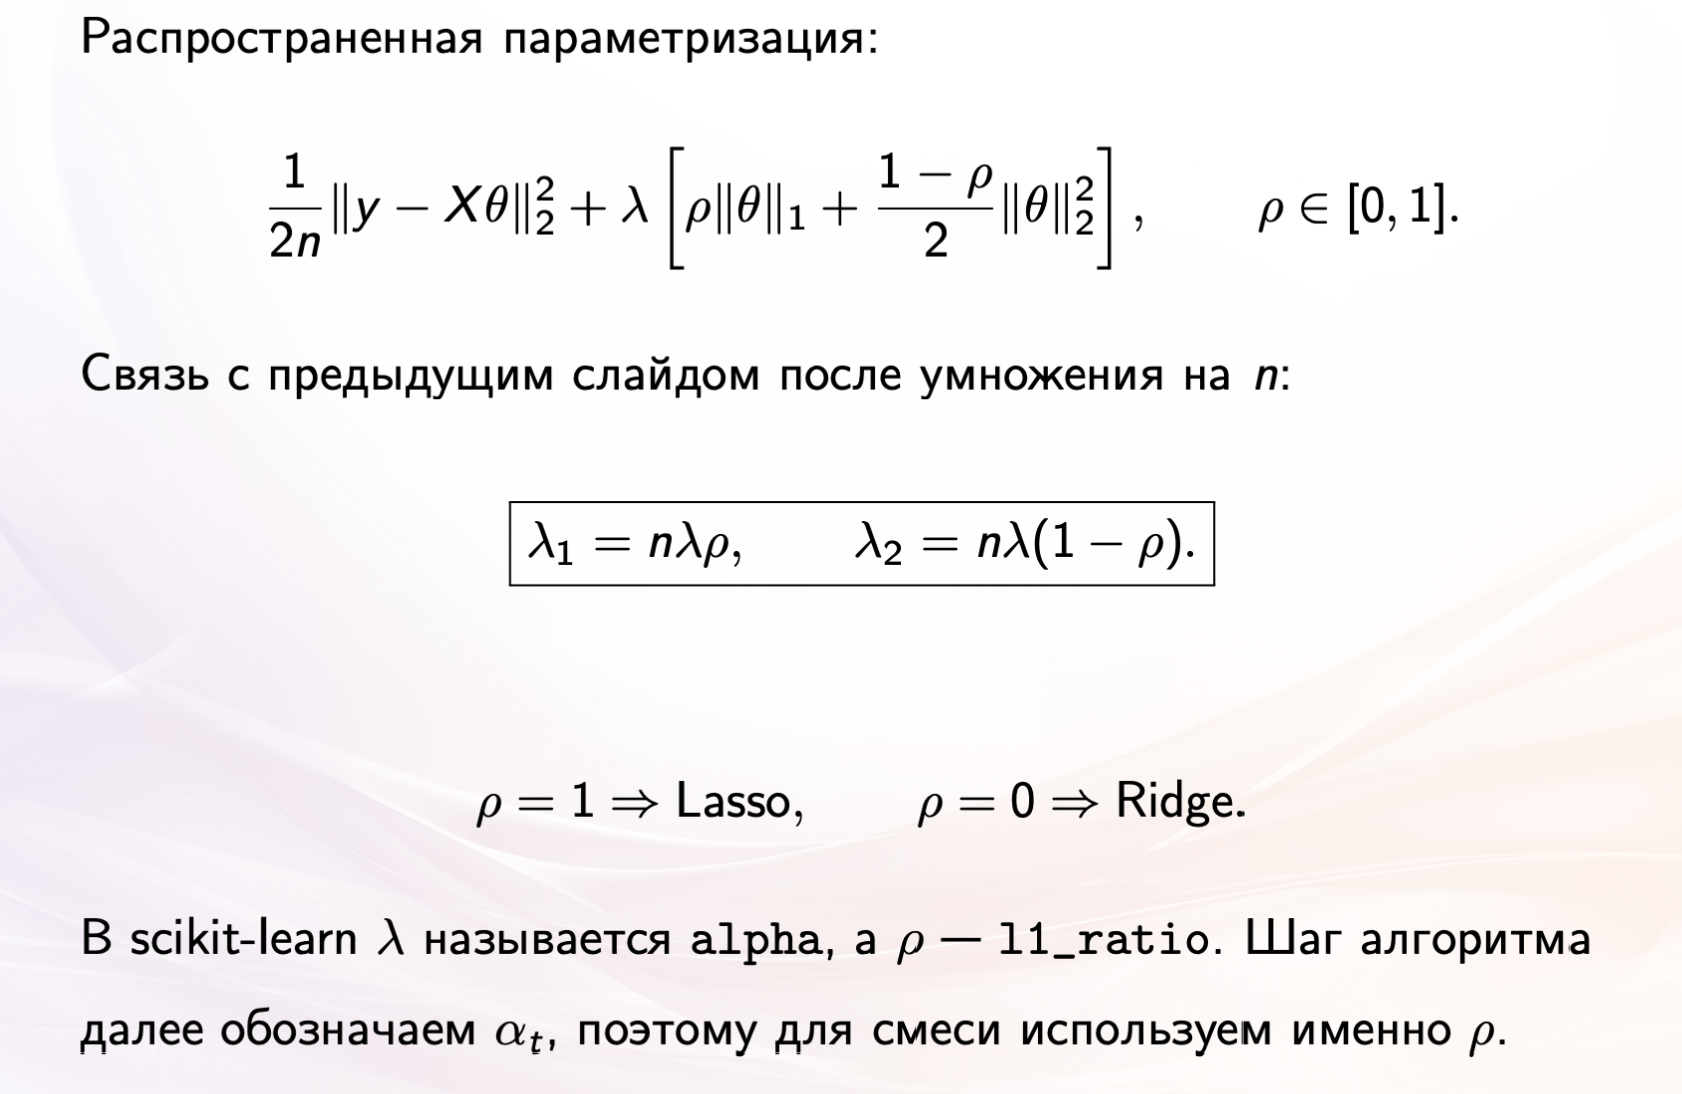

In [29]:
def train_alpha_grid(
    log_C_bounds: Tuple[float, float],
    resolution: int,
    data: Dict[str, Any],
    preproc_steps: List[Tuple[str, Any]],
    penalty: str | None = None, # я не использую penalty в своей функции, ибо как сказали мне Warnings которые мы стремились ми нимизировать, вместо penalty новомодно использовать l1_ratio
    solver: str = 'newton-cholesky',
    max_iter: int = 100,
    l1_ratio: float | None = None, # Я добавила аргумент, чтобы провести эксперимент ниже под номером 3 с комбинированной регуляризацией
) -> Tuple[List[np.ndarray], List[float], List[float]]:
    """Обучает модель LogisticRegression для разных значений параметра регуляризации C,
    сохраняет коэффициенты, вычисляет accuracy на обучающей и тестовой выборках.

    Args:
        log_C_bounds (Tuple[float, float]): кортеж с минимальным и максимальным значением log10(C) для сетки.
        resolution (int): число точек на сетке C.
        data (dict): словарь с обучающей и тестовой выборками (например, {'X_train': ..., 'y_train': ..., 'X_test': ..., 'y_test': ...}).
        preproc_steps (List[Tuple[str, Any]]): список шагов пайплайна.
        penalty (str): тип регуляризации ('l1', 'l2', 'elasticnet', 'none').
        solver (str): метод оптимизации параметров модели (см. аргумент `solver` у класса LogisticRegression).
        max_iter (int): обучение останавливается, если требуемая точность не достигнута за max_iter итераций.

    Returns:
        coefs_list (List[np.ndarray]): список массивов коэффициентов для каждого значения C.
        acc_train_list (List[float]): список accuracy на обучающей выборке для каждого значения C.
        acc_test_list (List[float]): список accuracy на тестовой выборке для каждого значения C.
    """

    coefs_list : List[np.ndarray] = [] # список массивов коэффициентов для каждого значения C.
    acc_train_list : List[float] = []  # список accuracy на обучающей выборке для каждого значения C.
    acc_test_list : List[float] = []   # список accuracy на тестовой выборке для каждого значения C.

    lower, upper = log_C_bounds
    for c in tqdm(np.logspace(lower, upper, num=resolution)):
        if l1_ratio is not None:
            lr_model_initialized = LogisticRegression(C=c, max_iter=max_iter, solver=solver, l1_ratio=l1_ratio)
        else:
            lr_model_initialized = LogisticRegression(C=c, max_iter=max_iter, solver=solver, penalty=None)
        # чтобы избежать warning, я оставила penalty='l2' по умолчанию, но буду использовать вместо него, как было сказано в warning: l1_ratio
        # Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet'
        lr_model_c = Pipeline(
            steps=preproc_steps + [
                ('estimator', lr_model_initialized)
            ]
        )
        lr_model_c.fit(data['X_train'], data['y_train'])

        predictions_train = lr_model_c.predict(data['X_train'])
        predictions_test = lr_model_c.predict(data['X_test'])

        acc_train_list.append(accuracy_score(data['y_train'], predictions_train))
        acc_test_list.append(accuracy_score(data['y_test'], predictions_test))

        coefs_list.append(lr_model_c.named_steps['estimator'].coef_ + [lr_model_c.named_steps['estimator'].intercept_])

    return coefs_list, acc_train_list, acc_test_list

Проведите эксперимент для 3-х разных моделей логистической регрессии с различными типами регуляризации:
1.  $L_1$-регуляризация
2.  $L_2$-регуляризация
3.  Комбинированная регуляризация с параметром `l1_ratio=0.5`.

>*Рекомендации*
>*   Подберите диапазоны значений для гиперпараметра `C`. Не берите слишком узкие, чтобы видеть на графике всю картину. Для слишком широких границ придётся брать больше точек.
>*   Вам не нужна очень частая сетка гиперпараметра `C`. При отладке кода можно вообще использовать сетку из 2-3 значений.
>*   Вы можете столкнуться с различными ошибками и `warning`-ами (например, неверный `solver`, отсутствие сходимости,  и т.д.). Постарайтесь настроить гиперпараметры модели таким образом, чтобы ошибки исчезли, а количество предупреждений было минимальным.

Напишем функцию, которая строит график зависимости точности от C

Проводим три эксперимента и строим графики

In [30]:
coefs_list1, acc_train_list1, acc_test_list1 = train_alpha_grid(
    log_C_bounds=(-6, 6),
    resolution = 5,
    data = {'X_train': X_train, 'y_train': y_train, 'X_test': X_test, 'y_test': y_test},
    preproc_steps = [ ('preprocessor', column_transformer)],
    penalty = None,  # l1_ratio=1 instead of penalty='l1'
    l1_ratio = 1.0,
    solver = 'saga',
    max_iter = 5000
)

  0%|          | 0/5 [00:00<?, ?it/s]

In [31]:
coefs_list2, acc_train_list2, acc_test_list2 = train_alpha_grid(
    log_C_bounds=(-6, 6),
    resolution = 5, # 5 штук
    data = {'X_train': X_train, 'y_train': y_train, 'X_test': X_test, 'y_test': y_test},
    preproc_steps = [ ('preprocessor', column_transformer)],
    penalty = None, # l1_ratio=0 instead of penalty='l2'
    l1_ratio = 0.0,
    solver = 'saga',
    max_iter = 5000
)

  0%|          | 0/5 [00:00<?, ?it/s]

In [32]:
coefs_list3, acc_train_list3, acc_test_list3 = train_alpha_grid(
    log_C_bounds=(-6, 6),
    resolution = 5,
    data = {'X_train': X_train, 'y_train': y_train, 'X_test': X_test, 'y_test': y_test},
    preproc_steps = [ ('preprocessor', column_transformer)],
    penalty = None, # l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet'
    l1_ratio=0.5,
    solver = 'saga',
    max_iter = 5000
)

  0%|          | 0/5 [00:00<?, ?it/s]

Выберите 8-15 признаков на своё усмотрение либо случайным образом. Нарисуйте треки соответствующих коэффициентов моделей в зависимости от `C`. Свободный коэффициент тоже стоит добавить на графики. Легенду можно сделать общую, если все графики помещаются на экране. Отразите в ней наименования признаков для соответствующих коэффициентов. Сделать красиво могут помочь заметки [отсюда](https://stackoverflow.com/questions/4700614/how-to-put-the-legend-outside-the-plot).

In [33]:
cnt_features = X_train_final.shape[1]
chosen_features = X_train_final.sample(n=10, random_state=42, axis=1).columns.tolist()
feature_indices = X_train_final.columns.get_indexer(chosen_features) # получили индексы каждого из признаков
print(chosen_features)

['subscribers_count_546.0', 'subscribers_count_1685.0', 'subscribers_count_4099.0', 'subscribers_count_1855.0', 'subscribers_count_12387.0', 'subscribers_count_1214.0', 'subscribers_count_1522.0', 'has_music_Unknown', 'subscribers_count_2164.0', 'subscribers_count_1383.0']


Я случайно выбрала 10 признаков и вот, что вижу 'subscribers_count_400.0',  subscribers_count - это вещественный признак, но он был принят как категориальный, хотя имел тип str изначально (я в начале добавила data_frame.info()), из-за этого в том числе может быть сильная мультиколлинеарность

Посмотрим теперь на веса каждой из трех моделей для этих признаков

In [34]:
def draw_model_weights(coefs_list, chosen_features, feature_indices, log_C_grid=np.logspace(-6, 6, num=5), experiment_num=1):
    plt.figure(figsize=(10, 7))

    coefs_list = np.array(coefs_list).squeeze()
    for feat, ind in zip(chosen_features, feature_indices):
        plt.plot(log_C_grid, coefs_list[:, ind], label=f"Веса модели для признака: {feat}")
        plt.plot(log_C_grid, coefs_list[:, -1], label=f"Свободн коэф для признака: {feat}") # coefs_list[-1] - это свободный член

    plt.title(f'Зависимость Весов от параметра C, Эксперимент №{experiment_num}')
    plt.xlabel('Параметр регуляризации C (log шкала)')
    plt.ylabel('Веса модели')
    plt.xscale('log')

    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left') # bbox to anchor по ссылке выше
    plt.show()

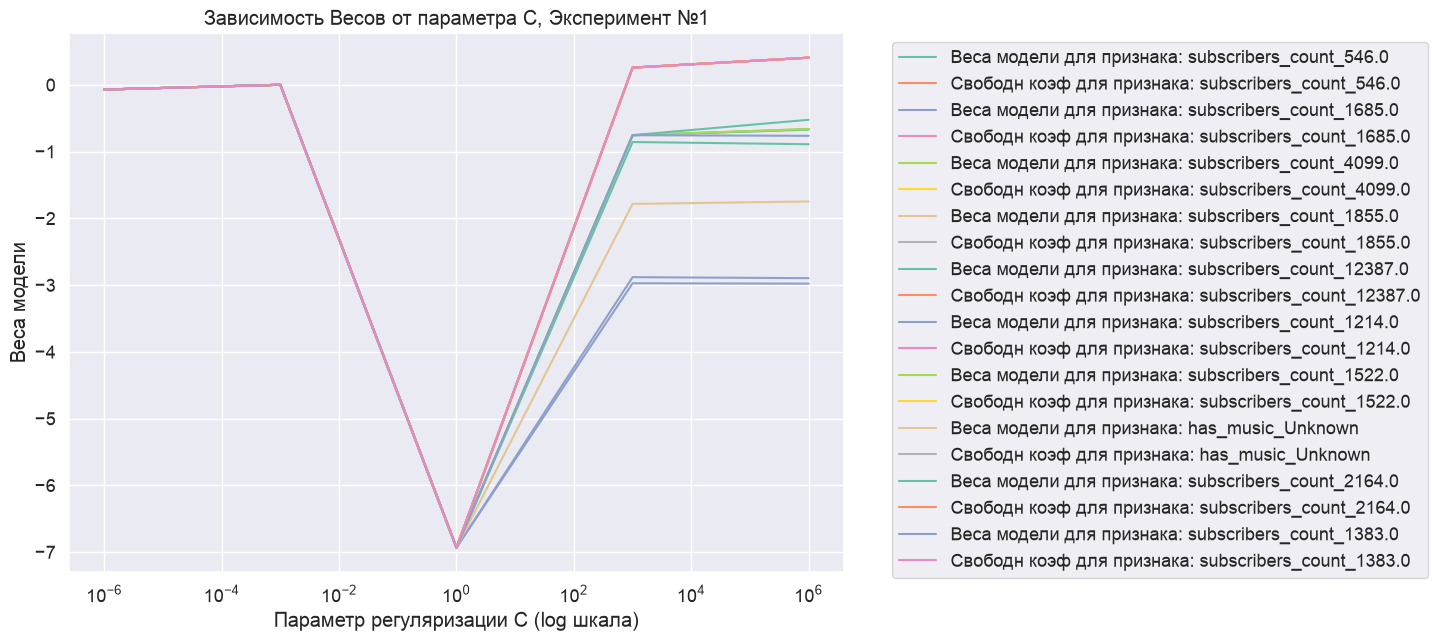

In [35]:
draw_model_weights(coefs_list1, chosen_features, feature_indices)

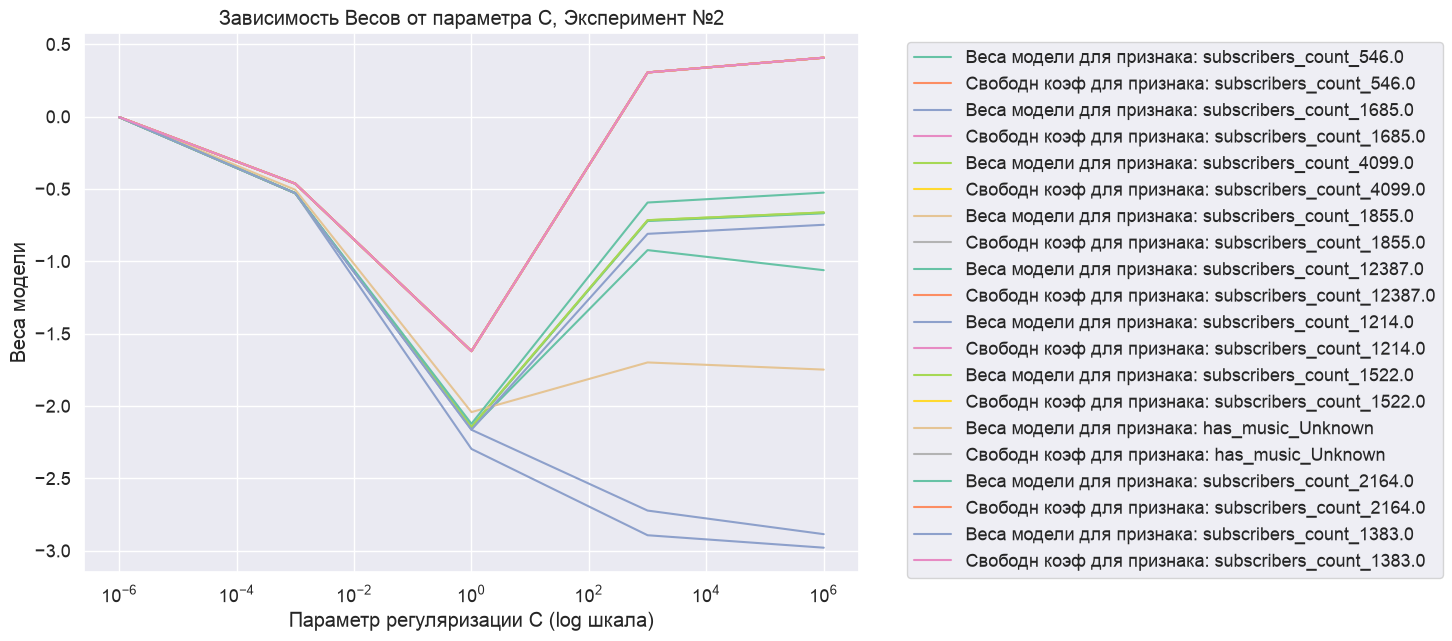

In [36]:
draw_model_weights(coefs_list2, chosen_features, feature_indices, experiment_num=2)

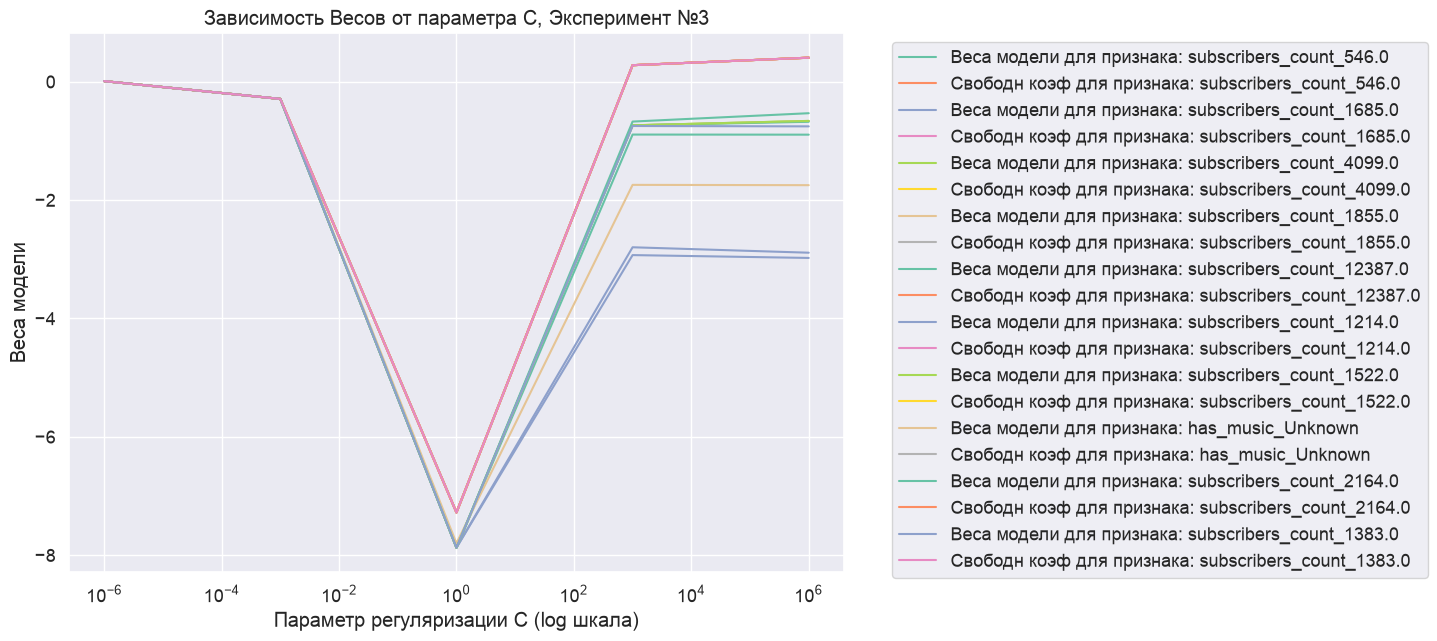

In [37]:
draw_model_weights(coefs_list3, chosen_features, feature_indices, experiment_num=3)

**Вывод:**

Введем обозначение: Функция эмпирического риска = C * лосс + штраф за веса (регуляризац)

Мы выше поняли, что:
* Чем больше $C$, тем больше модель обращает внимание на лосс, нежели на штраф за веса
* Чем меньше $C$ тем больше модель обращает внимание на регуляризацию

**Первый эксперимент: L1-регуляризация**

L1 - регуляризация как мы выяснили на лекции имеет свойство отбирать признаки. Мы можем пронаблюдать что с уменьшением $C$, то есть на графике если идти по оси абсцисс справа налево, наблюдается поочередный отбор признаков, а именно веса модели зануляются по очереди, не все сразу именно резко в ноль ушли, а сначала оди н, потом второй и так далее - это видно на графике.

**Второй эксперимент: L2-регуляризация**

L2 - регуляризация не отбирает признаки, но может сильно уменьшать веса.
При больших $C$, опять же, все внимание приковано к лоссу и его минимизации, чем меньше становится $C \in (10^{-12}, 10^0)$ можно видеть как веса стремятся к нулю, но еще не равны нулю. Когда $C < 10^{-12}$ слишком маленький лосс * C итак мелкое, поэтому очень сильно минимизируются веса - до такой степени что они загоняются в ноль

**Третий эксперимент: Elastic Net, половинка под L1, половинка под L2 регуляризацию**

По Elastic Net графику (третьему) явно видно, что и не как на L1 графике (все веса резко поочередно ушли в ноль), и не как с L2, где веса сначала изгибались около нуля, а потом ушли в ноль. На этом графике наблюдается поведение - среднее между предыдущими: по мере уменьшения $C$ (справа налево) можно видеть как веса сначала чуть-чуть изогнулись около нуля, а затем ушли в ноль

Нарисуйте зависимости точности предсказания от `C` на обучающей и тестовой выборках. Скомпонуйте всё на 2-3 графиках. Горизонтальными линиями отметьте точность модели без регуляризации на тесте.

In [38]:
def dependency_accuracy_C(log_C_grid: np.ndarray, acc_train_list: List[float], acc_test_list: List[float], experiment_num: int = 1):
    plt.figure(figsize=(10, 7))
    plt.plot(log_C_grid, acc_train_list, label='Accuracy на трэйне')
    plt.plot(log_C_grid, acc_test_list, label='Accuracy на тесте')

    # модель без регурялизации мы обучали чуть выше и на тесте она выдала accuracy_score = 0.95
    plt.hlines(y=0.95, xmin=log_C_grid[0], xmax=log_C_grid[-1], color='red', linestyle='--', label="Accuracy на тесте без регуляризации y = 0.95")

    plt.title(f'Зависимость Accuracy от параметра C, Эксперимент №{experiment_num}')
    plt.xlabel('Параметр регуляризации C (log шкала)')
    plt.ylabel('Accuracy')
    plt.xscale('log')
    plt.yticks(np.arange(0.5, 1.01, step=0.03))
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left') # bbox to anchor по ссылке выше
    plt.show()

Обучим модел регуляризации, чтобы затем нарисовать на графике вертикальную линию точность модели на тесте бещ регуляризации

Рисуем графики зависимости точности от C

Для первого эксперимента

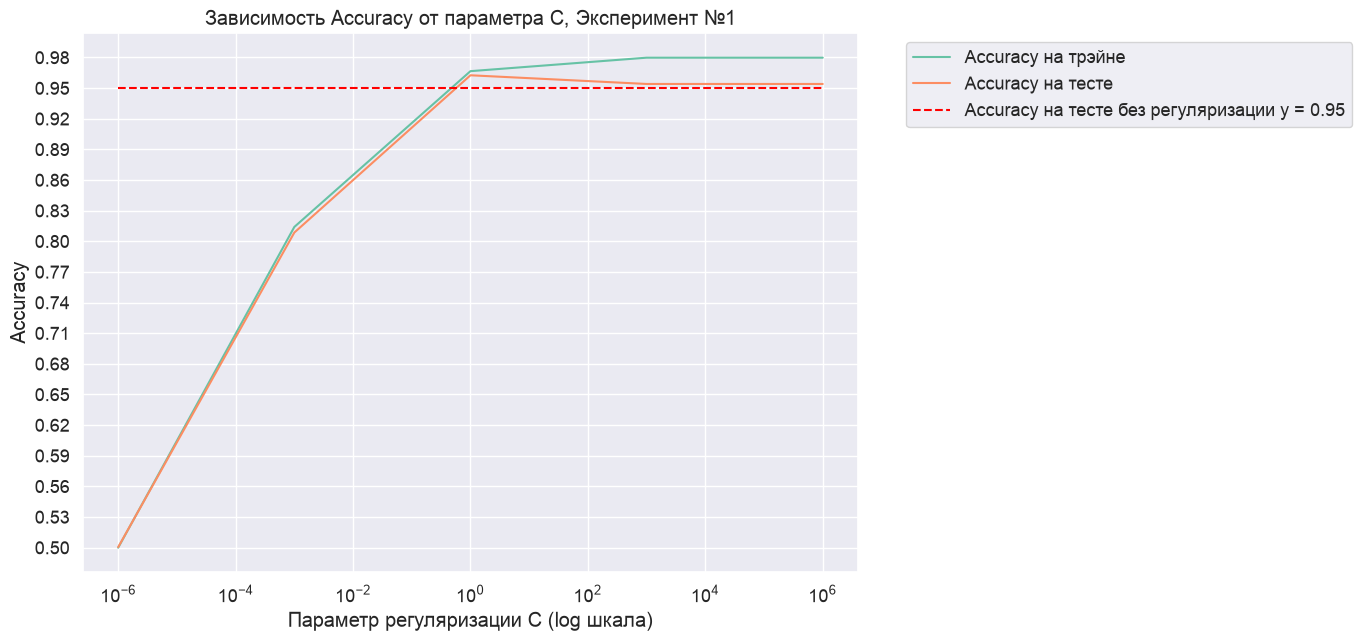

In [40]:
dependency_accuracy_C(np.logspace(-6, 6, num=5), acc_train_list1, acc_test_list1)

Для второго эксперимента

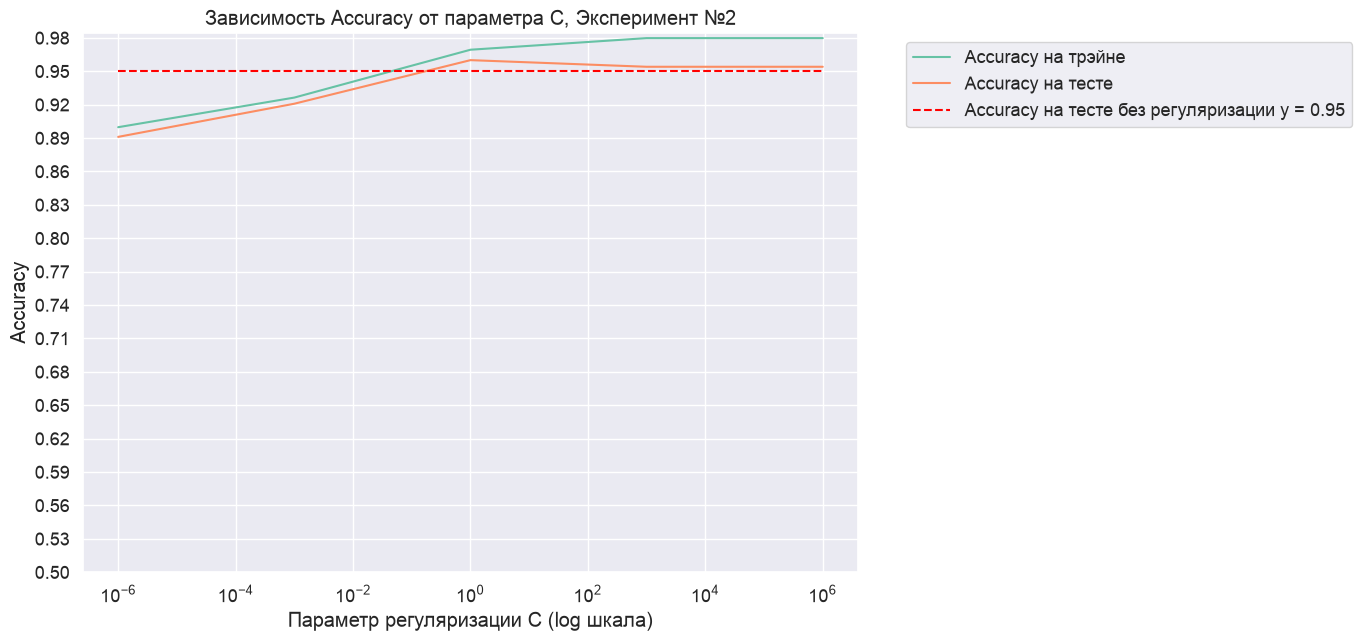

In [41]:
dependency_accuracy_C(np.logspace(-6, 6, num=5), acc_train_list2, acc_test_list2, 2)

Для третьего эксперимента

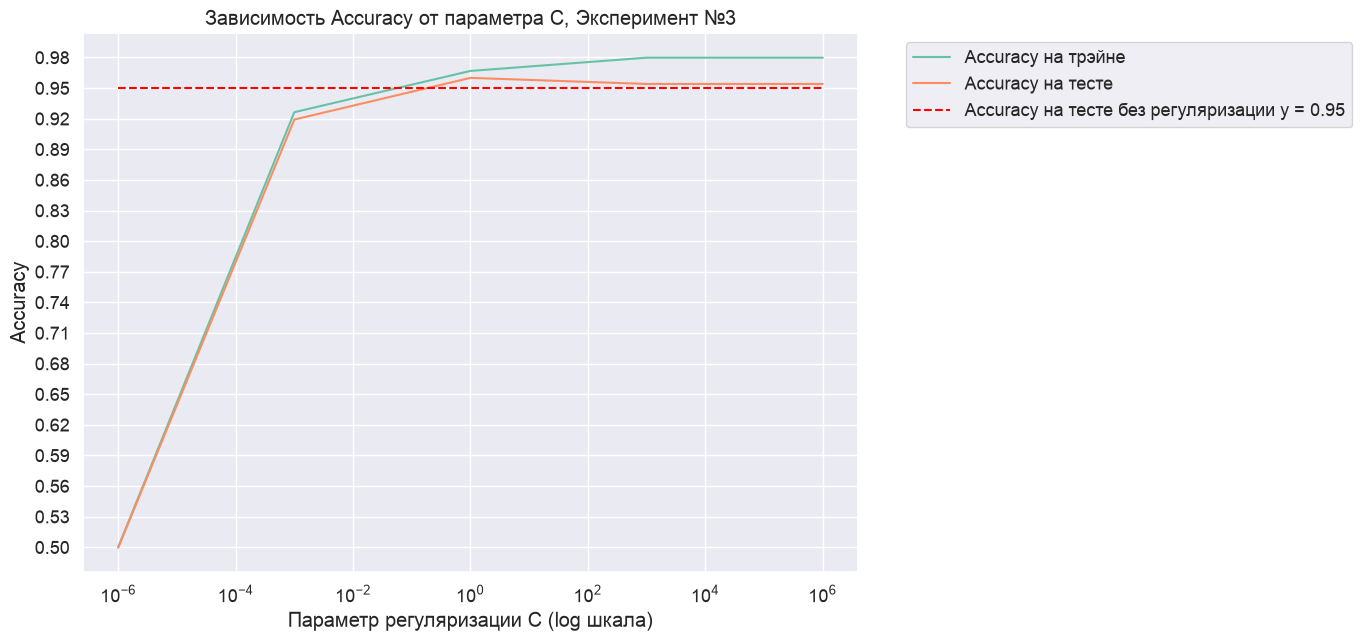

In [42]:
dependency_accuracy_C(np.logspace(-6, 6, num=5), acc_train_list3, acc_test_list3, 3)

Сделайте вывод. Есть ли польза от регуляризации с точки зрения метрики?

**Вывод:**

По построенным графикам видно:

* На первом графике (где эксперимент номер 1 с L1 регуляризацией), функция accuracy выглядит похожей на график сигмоиды
* На всех графиках видно, что точность на тесте после регуляризации стала выше порогового значения y = 0.95 (точность на тесте для лог регрессии без регуляризации). Получается, что от регуляризации польза есть (хотя бы |train_accuracy - test_accuracy| стало меньше)
* Но большой разницы на |train_accuracy - test_accuracy| между тремя регуляризациями (L1, L2, Elastic Net) я не вижу, у них у всех |train_accuracy - test_accuracy| = 0.02

**3.** **Число обусловленности**

Исследуйте зависимость числа обусловленности от параметра `C` для $L_2$-регуляризации. Постройте соответствующий график.

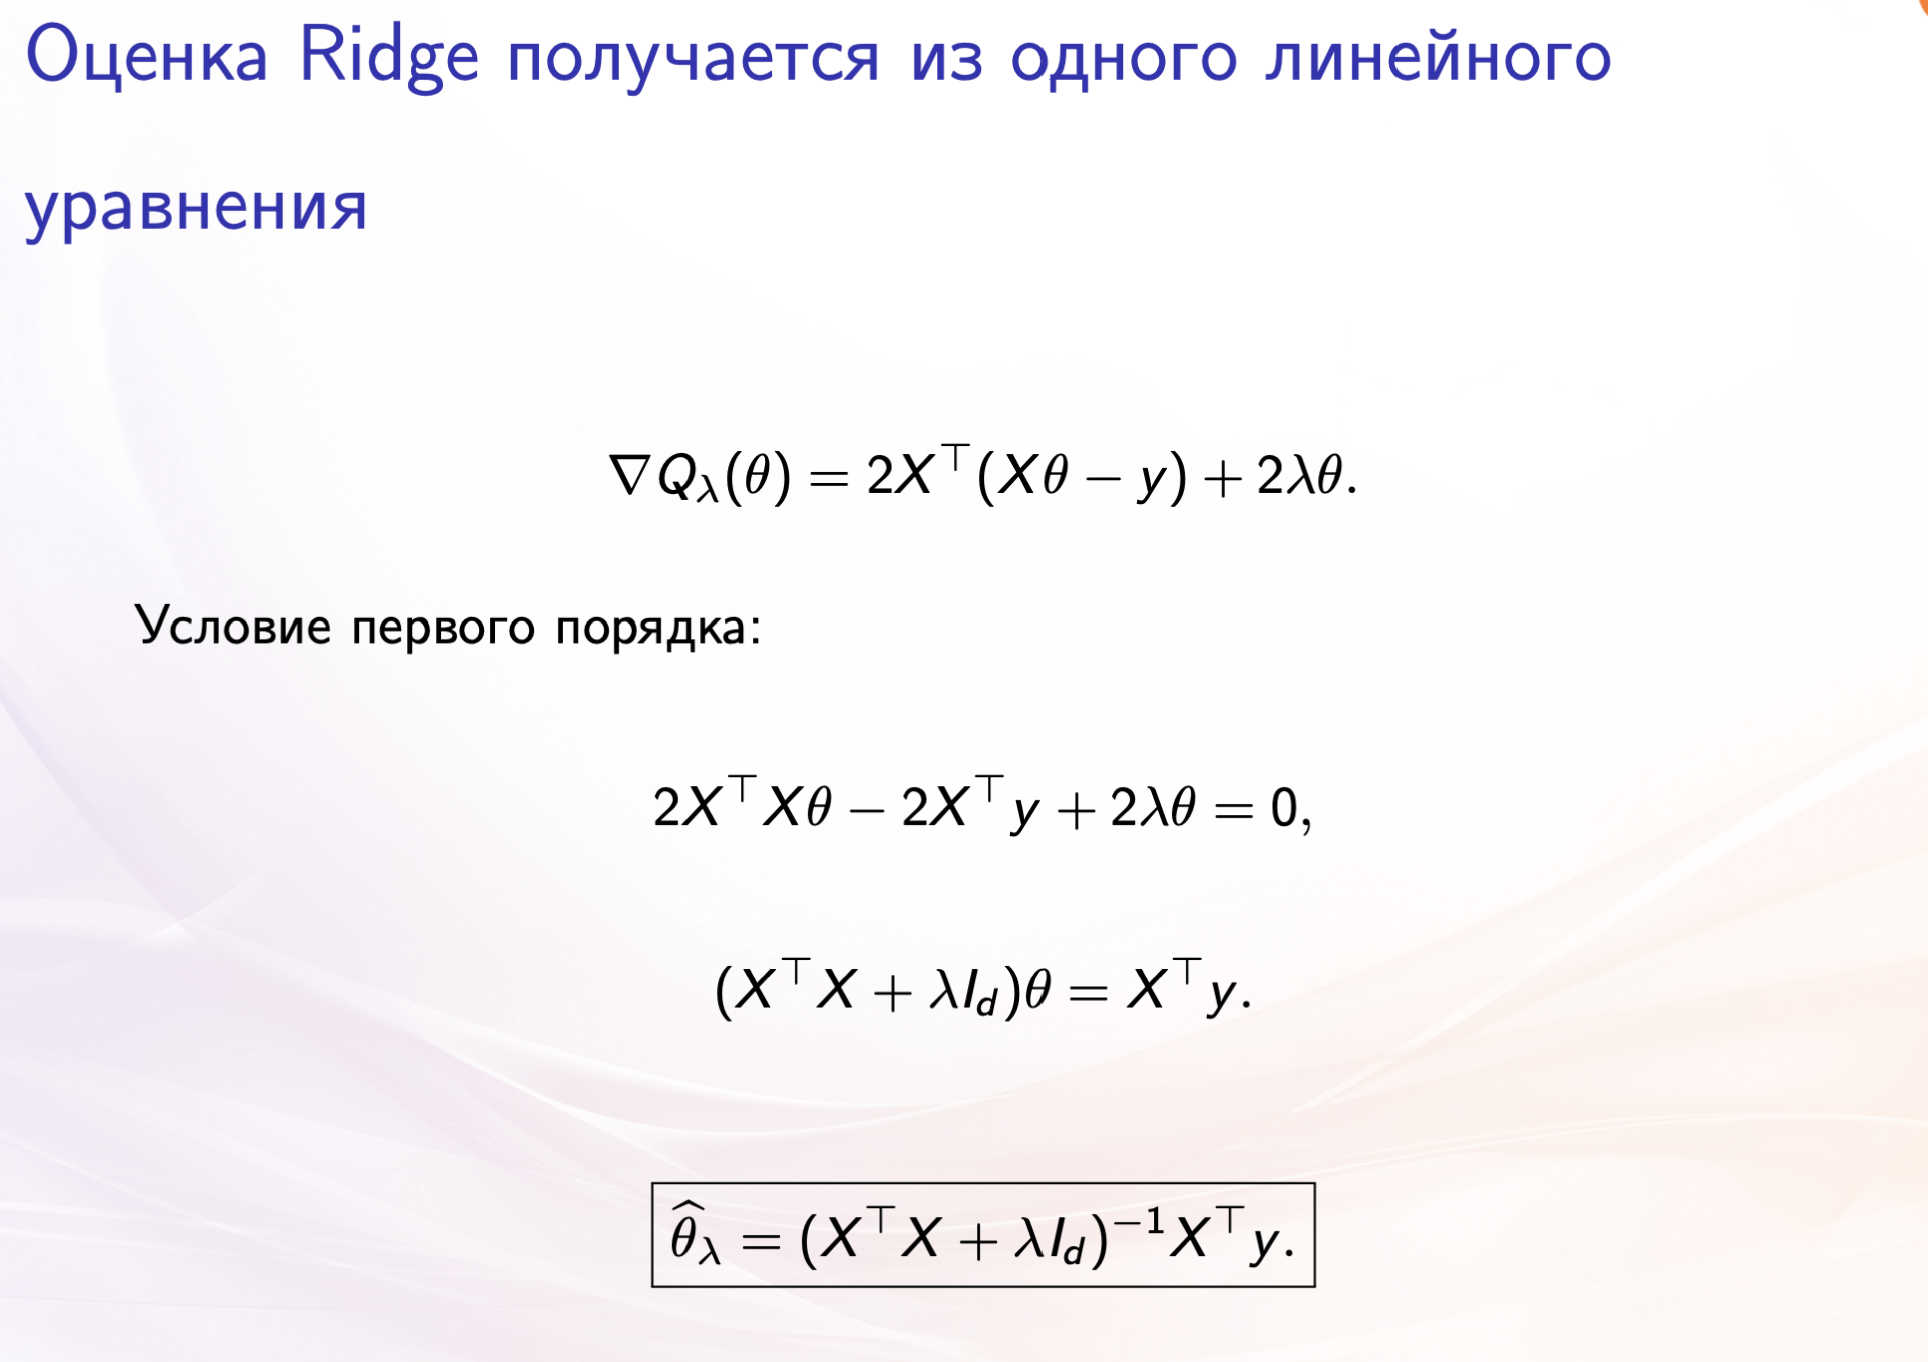

Наша функция эмпирического риска = C * лосс + регуляризация -> min $\Longleftrightarrow$ лосс + $\frac{1}{C}$ * регуляризация -> min

при рассмотрении Ridge-регуляризации (L2) мы работаем с матрицей $A = X^T * X + \alpha * I$, где $I$ - Identical Matrix

То есть имеем $\frac{1}{C} = \alpha$ - параметр регуляризации

CI = $\frac{\sqrt(\lambda_{\text{max}}(A))}{\sqrt(\lambda_{\text{min}}(A))}$, отметим, что

$\lambda(A) = \lambda(X^T * X + \alpha * I) = \lambda(X^T * X) + \alpha$

Значит CI = $\frac{\sqrt(\lambda_{\text{max}}(X^T * X) + \frac{1}{C})}{\sqrt(\lambda_{\text{min}}(X^T * X) + \frac{1}{C})}$

Подправим нашу старую функцию которая для разных параметров для логрегрессии обучала лог регрессию с помощью column трансформера и пайплайна, и немного изменим ее так, чтобы она теперь вовзвращала только список из Ci для разных C

In [43]:
import math

def train_alpha_grid(
    log_C_bounds: Tuple[float, float],
    resolution: int,
    data: Dict[str, Any],
    preproc_steps: List[Tuple[str, Any]],
) -> Tuple[List[np.ndarray], List[float], List[float]]:
    """Обучает модель LogisticRegression для разных значений параметра регуляризации C,
    сохраняет коэффициенты, вычисляет accuracy на обучающей и тестовой выборках.

    Args:
        log_C_bounds (Tuple[float, float]): кортеж с минимальным и максимальным значением log10(C) для сетки.
        resolution (int): число точек на сетке C.
        data (dict): словарь с обучающей и тестовой выборками (например, {'X_train': ..., 'y_train': ..., 'X_test': ..., 'y_test': ...}).
        preproc_steps (List[Tuple[str, Any]]): список шагов пайплайна.
        penalty (str): тип регуляризации ('l1', 'l2', 'elasticnet', 'none').
        solver (str): метод оптимизации параметров модели (см. аргумент `solver` у класса LogisticRegression).
        max_iter (int): обучение останавливается, если требуемая точность не достигнута за max_iter итераций.

    Returns:
        ci_list (List[float]): список значений CI на обучающей выборке для каждого значения C (на тесте считать нельзя, чтобы не было дата leakage, CI позволяет понять есть ли мультиколлинеарность в признаках и избавиться от нее, поэтому только на обуч выборке считаем и решаем какие признаки убрать, ибо к реальным тестовым данным доступа у нас быть не должно
    """

    ci_list : List[float] = []

    preproc_pipeline = Pipeline(steps=preproc_steps)
    X_final = preproc_pipeline.fit_transform(data['X_train'], data['y_train'])

    U, S, V_T = np.linalg.svd(X_final.T @ X_final)
    l_max = S[0] # S - это вектор сингулярных чисел отсорченых по убыванию
    l_min = S[-1]

    lower, upper = log_C_bounds
    for c in tqdm(np.logspace(lower, upper, num=resolution)):
        ci = math.sqrt(l_max + 1/c) / math.sqrt(l_min + 1/c)
        ci_list.append(ci)

    return ci_list

Обучаем модель с L2-регуляризацией и расчитываем CI

In [49]:
ci_list2 = train_alpha_grid(
    log_C_bounds=(-10, 5),
    resolution = 40, # 40 штук
    data = {'X_train': X_train, 'y_train': y_train, 'X_test': X_test, 'y_test': y_test},
    preproc_steps = [ ('preprocessor', column_transformer)]
)

  0%|          | 0/40 [00:00<?, ?it/s]

Теперь строим график зависимости

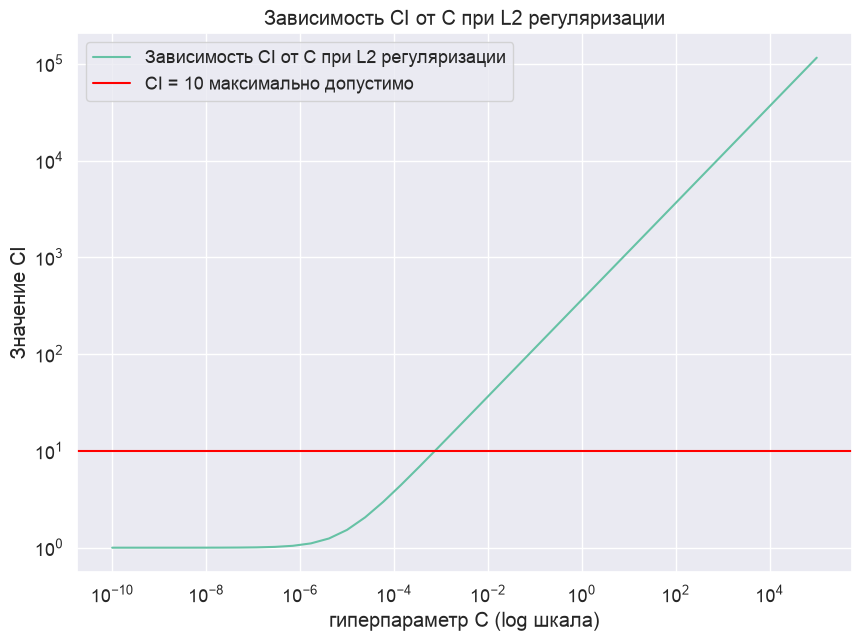

In [50]:
plt.figure(figsize=(10, 7))
plt.plot(np.logspace(-10, 5, 40), ci_list2, label='Зависимость CI от C при L2 регуляризации')
plt.axhline(y=10, color='red', label='CI = 10 максимально допустимо')

plt.xlabel('гиперпараметр C (log шкала)')
plt.ylabel('Значение CI')
plt.title('Зависимость CI от C при L2 регуляризации')
plt.xscale('log')
plt.yscale('log')
plt.legend()
plt.show()

Сделайте вывод. О чём свидетельствует полученная зависимость?

**Вывод:**

**На графике видно:**

При очень маленкьих $C \in [10^{-10}, 10^{-3}]$ CI имеет допустимое значение $\leq 10$ и к тому же стремится к 1 (своему идеальному значению), почему так?

Потому что при маленьких C обращается сильное внимание на регуляризацию (Loss + 1/C * regularization -> min) и L2-регуляризация ценой смещения оценки весов модели с мультиколлинеарностью борется, не давая весам разрастаться.

При больших C, соответсвенно, регуляризация не такая сильная. Это значит, что мультиколлинеарность проявляется во всей красе: CI - большой.

**Эта зависимость свидетельствует о том, что**

В данных есть очень сильная мультиколлинеарность, так как видно что CI может достигать значения $10^5 >> 30$! (я уверена, что это все из-за фичи subscribers_count, которая не была переведена из стокового в числовой формат, являясь при этом вещественной, и была закодирована как Categorial feature с помощью OneHotEncoder, поэтому при исследовании данных на тип данных и значения в колонках надо обращать внимание!), при этом есть свидетелство того, что Ridge, хоть и платит цену смещенной оценки весов, но борется с этой мультиколлинеарностью, помогая модели быть более устойчивой (при небольшом шуме в данных, веса модели не очень сильно меняются - это есть устойчивость)

**4.** **Разброс коэффициентов**

Рассмотрите **2 модели:** логистическая регрессия с регуляризацией по-умолчанию и с `penalty=None`. Каждую модель обучите 500 раз при различных разбиениях на обучающую и тестовую выборки. Сохраните коэффициенты для выбранных ранее признаков. Подсчитайте усреднённую метрику качества и визуализируйте распределение каждого коэффициента. Не забудьте про пайплайн.

> Визуализацию предлагается сделать виде сетки графиков. На каждом изобразите **ядерные оценки плотности** для соответствующего коэффициента обеих моделей.

In [51]:
from sklearn.model_selection import ShuffleSplit

preproc_steps = [
    ('preprocessor', column_transformer) # теперь в шагах препроцессинга только один column_ransformer, который и concat который мы делалаи за нас сделает
]

def train_500_times(lr_model_initialized, X_train, X_test, y_train, y_test):
    """Принимает на вход lr_model - модель логит регрессии"""
    rs = ShuffleSplit(n_splits=500, test_size=0.2, random_state=42)

    mean_accuracy_train = 0 # усредненная метрика качества для трэйн
    mean_accuracy_test = 0  # усредненная метрика качества для тест
    coefs_list = [] # значения коэффициентов выбранных на кажд итерации
    # coefs_list[i][j] i -номер итерации цикла ниже, j - номер признака

    for fold_idx, (train_idx, test_idx) in enumerate(rs.split(X, y)):
        X_train, X_test = X[train_idx], X[test_idx]
        y_train, y_test = y[train_idx], y[test_idx]

        lr_model_c = Pipeline(
            steps=preproc_steps + [
                ('estimator', lr_model_initialized)
            ]
        )
        lr_model_c.fit(X_train, y_train)

        predictions_train = lr_model_c.predict(X_train)
        predictions_test = lr_model_c.predict(X_test)

        mean_accuracy_train += accuracy_score(y_train, predictions_train)
        mean_accuracy_test += accuracy_score(y_test, predictions_test)

        coefs_list.append( # сохраняем коэфы для выбранных признаков
            lr_model_c.named_steps['estimator'].coef_[feature_indices] +
            [lr_model_c.named_steps['estimator'].intercept_[feature_indices]]
        )
    mean_accuracy_train /= 500
    mean_accuracy_test /= 500
    return mean_accuracy_train, mean_accuracy_test, coefs_list

Напишем функцию которая будет рисовать распределение коэффициентов

In [52]:
def draw_weights_hist(coefs_list):
    fig, axes = plt.figure(nrows=len(chosen_features), ncols=1)
    coefs_list = np.array(coefs_list).squeeze()
    i = 0
    for fet_num in feature_indices:
        axes[i].hist(coefs_list[:, i], bins=30, edgecolor='black', alpha=0.7)
        plt.xlabel(f'Значение коэффициента для признака №{fet_num}')
        plt.ylabel('Частота (количество итераций), когда такое значение коэфа встречалось')
        plt.title(f'Распределение коэффициента признака №{fet_num} по 500 разбиениям на train и test')
        plt.show()
        i += 1

Первая модель: penalty по умолчанию = L2 (с L2 регуляризацией, функция эмпирического риска как в задании 3)

In [53]:
lr_model_default_penalty = LogisticRegression() # по умолчанию, как я узнала выше, penalty=l2

mean_accuracy_train1, mean_accuracy_test1, coefs_list1 = train_500_times(lr_model_default_penalty, X_train, X_test, y_train, y_test)
print(f"mean_accuracy_train={mean_accuracy_train1}:.2f")
print(f"mean_accuracy_test={mean_accuracy_test1}:.2f")

draw_weights_hist(coefs_list1)

KeyError: "None of [Index([3686, 4618, 3455, 5347, 3523, 4528, 4086, 5772, 5166, 2859,\n       ...\n       4426, 5334,  466, 5734, 3092, 3772, 5191, 5226, 5390,  860],\n      dtype='int64', length=4699)] are in the [columns]"

Вторая модель: penalty = None (без регуляризации, просто минимизации кросс энтропии для Лог Регрессии)

In [55]:
lr_model_penalty_none = LogisticRegression(penalty=None)

mean_accuracy_train2, mean_accuracy_test2, coefs_list2 = train_500_times(lr_model_penalty_none, X_train, X_test, y_train, y_test)
print(f"mean_accuracy_train={mean_accuracy_train2}:.2f")
print(f"mean_accuracy_test={mean_accuracy_test2}:.2f")

draw_weights_hist(coefs_list2)

KeyError: "None of [Index([3686, 4618, 3455, 5347, 3523, 4528, 4086, 5772, 5166, 2859,\n       ...\n       4426, 5334,  466, 5734, 3092, 3772, 5191, 5226, 5390,  860],\n      dtype='int64', length=4699)] are in the [columns]"

Какой модели вы больше доверитесь при интерпретации коэффициентов? Почему разработчики sklearn по-умолчанию добавили в логистическую регрессию небольшую $L_2$-регуляризацию? В чём заключается её польза? Порассуждайте над этими вопросами и попробуйте написать интерпретацию выведенных коэффициентов.

**Вывод**

---
© 2026 команда <a href="https://thetahat.ru/">ThetaHat</a> для DS-потока